# Capstone Project — Analisis Absensi & Honor Tutor Bimbel
**ID Team:** A26-CS035

**Tujuan:** membersihkan data absensi sesi les, menghitung estimasi honor tutor, menganalisis aktivitas tutor/murid/mata pelajaran, serta menyiapkan data bersih untuk tim AE.

**Dataset:** absensi_gabungan.csv, master_murid.csv, master_tutor.csv, master_subjects.csv, tarif_gaji.csv

**Cara menjalankan notebook:**
1. Siapkan 5 file CSV: `absensi_gabungan.csv`, `master_murid.csv`, `master_tutor.csv`, `master_subjects.csv`, `tarif_gaji.csv`.
2. Jalankan **Runtime → Run all**, lalu unggah kelima file saat diminta.
3. Hasil ekspor diunduh otomatis sebagai `hasil_capstone.zip` di akhir notebook.

*Catatan: data disimpan di penyimpanan sementara Colab (`/content`) dan akan terhapus saat runtime terputus atau di-reset, sehingga file perlu diunggah ulang setiap sesi.*

## Pertanyaan Bisnis

Analisis ini menjawab pertanyaan-pertanyaan berikut. Seluruh analisis bisnis menggunakan data tahun 2026. Data 2025 hanya dipakai untuk pemeriksaan kualitas data.

### Terkait Honor Tutor:
1. **Bagaimana tren pendapatan kotor, biaya administrasi, dan pendapatan bersih tutor per bulan sepanjang 2026?** Pada bulan apa pengeluaran honor paling tinggi dan paling rendah?

### Terkait Aktivitas Tutor:
2. **Siapa tutor dengan jumlah sesi terbanyak, dan bagaimana tren aktivitas bulanan mereka?** Apakah beban mengajar terpusat pada beberapa tutor saja?

### Terkait Komposisi Murid:
3. **Bagaimana komposisi murid aktif menurut jenjang dan kelas?** Jenjang mana yang menjadi segmen terbesar?
4. **Bagaimana perkembangan jumlah murid aktif dan murid baru setiap bulan?**

### Terkait Mata Pelajaran:
5. **Mata pelajaran apa yang paling banyak diambil, pada jenjang apa, dan bagaimana trennya per bulan?**

### Terkait Operasional Bimbel:
6. **Bagaimana perubahan jumlah sesi dan total jam mengajar dari bulan ke bulan?** Apakah ada pola musiman, misalnya menjelang ujian atau saat libur sekolah?

### Terkait Pemodelan:
7. **Klasifikasi:** Dapatkah pola sesi seorang murid memprediksi apakah murid tersebut akan **churn/tidak aktif pada bulan berikutnya**?
8. **Forecasting:** Berapa **prediksi jumlah sesi pada bulan berikutnya** (November 2026), dan metode sederhana mana yang paling akurat?
9. **Clustering:** Dapatkah tutor dikelompokkan berdasarkan pola aktivitasnya (jumlah sesi, jam mengajar, jumlah murid, dan bulan aktif)?

## Aturan Bisnis

Aturan berikut telah disepakati tim dan diterapkan pada seluruh perhitungan.

**Cakupan data**
- Setiap anak memiliki ID murid berbeda untuk setiap kelas, sehingga jumlah ID murid menunjukkan "identitas murid per kelas", bukan jumlah anak.

**Tarif**
- Tarif per jam ditentukan oleh jenjang murid: PAUD & TK Rp40.000, SD 1-3 Rp60.000, SD 4-6 Rp80.000, SMP Rp100.000, SMA Rp120.000.

**Jam honor**
- Durasi < 30 menit: tidak dibayar.
- Durasi 30–59 menit: dibayar penuh 1 jam.
- Durasi ≥ 60 menit: jam penuh, ditambah 0,5 jam bila sisa menit ≥ 30 (contoh: 89 menit = 1 jam; 90 menit = 1,5 jam; 150 menit = 2,5 jam).

**Biaya administrasi**
- Rp10.000 × jam honor yang dibulatkan ke atas: Rp10.000 hingga 89 menit, Rp20.000 mulai menit ke-90, Rp30.000 mulai menit ke-150, dan seterusnya naik setiap 60 menit.
- Honor bersih = tarif × jam honor − biaya administrasi.

**Sesi yang ditinjau dan tidak dibayar**
- Durasi < 30 menit atau > 180 menit.
- Jam mulai sebelum 07.00 atau setelah 21.00.
- Kolom tahun berbeda dengan tahun tanggal les.
- Kemungkinan duplikat (tutor, murid, mata pelajaran, tanggal, jam mulai, dan durasi sama): salinan pertama yang dikirim tetap dibayar, salinan berikutnya tidak dibayar.

**Definisi analisis**
- Setiap sesi dihitung satu kali; salinan duplikat tidak ikut dalam total bulanan, peringkat tutor, maupun pemodelan.
- Murid aktif: ID murid dengan minimal 1 sesi pada bulan tersebut.
- Murid tidak aktif bulan berikutnya: murid aktif yang tidak memiliki sesi pada bulan berikutnya.

## Import Packages/Library

In [ ]:
from pathlib import Path
from datetime import datetime, date, timezone, timedelta
import json
import math
import re
import uuid

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Machine learning (used in the classification, forecasting and clustering sections)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, confusion_matrix,
    mean_absolute_error, mean_squared_error, silhouette_score,
)

try:
    from IPython.display import display
except ImportError:
    display = print

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 180)
pd.set_option("display.max_colwidth", 80)

## Gathering Data

### Konfigurasi Folder Data dan Output

In [ ]:
PROJECT_DIR = Path.cwd()
if not (PROJECT_DIR / "Data").exists() and "__file__" in globals():
    possible_root = Path(__file__).resolve().parent.parent
    if (possible_root / "Data").exists():
        PROJECT_DIR = possible_root

DATA_DIR = PROJECT_DIR / "Data"
OUTPUT_DIR = PROJECT_DIR / "output_datascience_colab"
DATA_OUTPUT_DIR = OUTPUT_DIR / "data"
REPORT_DIR = OUTPUT_DIR / "reports"

# Setiap sesi Colab baru: unggah 5 file CSV bila folder Data belum ada
try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB and not any(DATA_DIR.glob("*.csv")):
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    print("Pilih 5 file CSV: absensi_gabungan, master_murid, master_tutor, master_subjects, tarif_gaji")
    uploaded = files.upload()
    for name in uploaded:
        Path(name).replace(DATA_DIR / name)  # pindahkan dari /content ke /content/Data

if not DATA_DIR.exists():
    raise FileNotFoundError(f"Folder data tidak ditemukan: {DATA_DIR}")

for output_folder in [OUTPUT_DIR, DATA_OUTPUT_DIR, REPORT_DIR]:
    output_folder.mkdir(parents=True, exist_ok=True)

print("Folder sumber:", DATA_DIR)
print("Folder hasil :", OUTPUT_DIR)
print("File CSV yang ditemukan:", sorted(p.name for p in DATA_DIR.glob("*.csv")))

Folder sumber: /content/Data
Folder hasil : /content/output_datascience_colab
File CSV yang ditemukan: ['absensi_gabungan.csv', 'master_murid.csv', 'master_subject.csv', 'master_tutor.csv', 'tarif_gaji.csv']


### Load Sumber Data

In [ ]:
def find_source_file(primary_name, alternate_name=None):
    candidate = DATA_DIR / primary_name
    if candidate.exists():
        return candidate
    if alternate_name:
        alternate = DATA_DIR / alternate_name
        if alternate.exists():
            return alternate
    raise FileNotFoundError(f"Tidak ditemukan: {candidate.name}")

attendance_path = find_source_file("absensi_gabungan.csv")
student_path = find_source_file("master_murid.csv")
tutor_path = find_source_file("master_tutor.csv")
subject_path = find_source_file("master_subjects.csv", "master_subject.csv")
tariff_path = find_source_file("tarif_gaji.csv")

READ_OPTIONS = {"sep": None, "engine": "python", "encoding": "utf-8-sig"}

def read_source(path, as_text=True):
    """Baca CSV; lewati baris header palsu 'Column1, Column2, ...' bila ada."""
    options = {**READ_OPTIONS, **({"dtype": "string"} if as_text else {})}
    frame = pd.read_csv(path, **options)
    if all(str(column).startswith("Column") for column in frame.columns):
        frame = pd.read_csv(path, skiprows=1, **options)
    return frame

df_absensi_raw = read_source(attendance_path)
df_murid = read_source(student_path)
df_tutor = read_source(tutor_path)
df_subject = read_source(subject_path)
df_tarif = read_source(tariff_path, as_text=False)  # hourly_rate harus angka

datasets = {
    "absensi_gabungan": df_absensi_raw,
    "master_murid": df_murid,
    "master_tutor": df_tutor,
    "master_subject": df_subject,
    "tarif_gaji": df_tarif,
}

## Assessing Data

### Data Understanding

In [ ]:
for nama, frame in datasets.items():
    print(f"\n{'=' * 80}\n{nama}: {frame.shape[0]:,} baris × {frame.shape[1]} kolom")
    print("Kolom:", frame.columns.tolist())
    frame.info()
    print("Statistik deskriptif:")
    display(frame.describe(include="all").T)
    print("Missing values:")
    missing = pd.DataFrame({
        "jumlah_null": frame.isnull().sum(),
        "persentase_null": (frame.isnull().mean() * 100).round(2),
    })
    display(missing)
    print("Baris duplikat persis:", int(frame.duplicated().sum()))
    display(frame.head(3))


absensi_gabungan: 5,035 baris × 14 kolom
Kolom: ['id', 'submitted_at', 'nama_tutor', 'tutor_id', 'nama_murid', 'student_id', 'kelas', 'asal_sekolah', 'mata_pelajaran', 'subject_id', 'tanggal_les', 'durasi_les', 'dokumentasi', 'tahun']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5035 entries, 0 to 5034
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   id              5035 non-null   string
 1   submitted_at    5035 non-null   string
 2   nama_tutor      5035 non-null   string
 3   tutor_id        5035 non-null   string
 4   nama_murid      5035 non-null   string
 5   student_id      5026 non-null   string
 6   kelas           5035 non-null   string
 7   asal_sekolah    5035 non-null   string
 8   mata_pelajaran  5035 non-null   string
 9   subject_id      5035 non-null   string
 10  tanggal_les     5035 non-null   string
 11  durasi_les      5034 non-null   string
 12  dokumentasi     5035 non-null   stri

,count,unique,top,freq
id,5035,5035,473dc2777a6e47b7a706cca10a52bbd5,1
submitted_at,5035,5035,2025-06-16 09:59:00.264068,1
nama_tutor,5035,37,Aisyah,491
tutor_id,5035,37,6820e321cfe9457397fa30dd9612cdb4,491
nama_murid,5035,115,Alfatharizky,333
student_id,5026,193,5c2090d3e4c34c87b85f921796181b7a,235
kelas,5035,14,Kelas 1,936
asal_sekolah,5035,55,SDIT Arafah,1612
mata_pelajaran,5035,288,Matematika,811
subject_id,5035,288,8cee3629d6704cc691cab0949f8a93d7,811


Missing values:


,jumlah_null,persentase_null
id,0,0.00
submitted_at,0,0.00
nama_tutor,0,0.00
tutor_id,0,0.00
nama_murid,0,0.00
student_id,9,0.18
kelas,0,0.00
asal_sekolah,0,0.00
mata_pelajaran,0,0.00
subject_id,0,0.00


Baris duplikat persis: 0


,id,submitted_at,nama_tutor,tutor_id,nama_murid,student_id,kelas,asal_sekolah,mata_pelajaran,subject_id,tanggal_les,durasi_les,dokumentasi,tahun
0,473dc2777a6e47b7a706cca10a52bbd5,2025-06-16 09:59:00.264068,Desty Wahdini,6daa16aa6e13430f8fabfd153fa48628,Olin,862cdfac370d493ea3d70104f4c56ebf,Kelas 4,SDN 5 Baamang Hulu,Matematika,8cee3629d6704cc691cab0949f8a93d7,2025-06-16,19.00-20.00,https://example.com/dummy/2025/473dc2777a6e47b7a706cca10a52bbd5,2025
1,2681a7296e4149768d6cf41b409c6a02,2025-08-29 19:24:31.717218,Tiara Pebrianti,147fa0de09774169abb6979a3624001a,Hana,7071ce8f4f704453ba172ad091cc1d30,Kelas 6,SDIT Arafah,Matematika,8cee3629d6704cc691cab0949f8a93d7,2025-08-27,14.00 - 15.00,https://example.com/dummy/2025/2681a7296e4149768d6cf41b409c6a02,2025
2,31284822d7bc47b3a9d72021d6c60457,2025-09-19 17:52:52.120875,Nasywa,1bd2f25045ee4a90a4c372c876bc9360,Akbar,edd1a52b965a409ca4b358a653c9586e,Kelas 3,SDIT Arafah,"Mengaji, Tajwid, dan Hafalan",d9b33948782f4255b93f07a85f6d1cbf,2025-09-19,15.30-16.30,https://example.com/dummy/2025/31284822d7bc47b3a9d72021d6c60457,2025


... (20 outputs left out)

Missing values:


,jumlah_null,persentase_null
education_level,0,0.0
hourly_rate,0,0.0


Baris duplikat persis: 0


,education_level,hourly_rate
0,PAUD,40000
1,TK,40000
2,SD 1-3,60000


**Insight – Data Understanding**

- **Data absensi** berisi **5.035 sesi** dengan **14 kolom**: 2.963 sesi (58,8%) di tahun 2026 dan 2.072 sesi (41,2%) di tahun 2025. Tanggal les berada pada rentang 2025-02-05 hingga 2026-10-21.
- **Tabel master** berisi **193 ID murid**, **37 tutor**, dan **23 mata pelajaran**. Tabel tarif (dummy) memiliki **6 jenjang** (Rp40.000–Rp120.000 per jam; rata-rata Rp73.333).
- **Data kosong sangat sedikit**: hanya **9 sel `student_id`** (0,18%) dan **1 sel `durasi_les`** (0,02%) yang kosong. Tabel master dan tarif tidak memiliki nilai kosong.
- **Tidak ada duplikat**: tidak ada baris duplikat persis di semua tabel, dan seluruh 5.035 `id` sesi bersifat unik.
- **Jumlah ID murid ≠ jumlah anak.** Master murid berisi 193 ID tetapi hanya 113 nama unik. Satu anak dapat memiliki beberapa ID untuk kelas yang berbeda (contoh: satu nama muncul di Kelas 1, 2, dan 3 pada sekolah yang sama). Karena itu analisis menyebutnya "identitas murid", bukan "jumlah murid".
- **Format tidak seragam**: `tanggal_les` memiliki 497 nilai unik dan `durasi_les` 726 nilai unik dengan format beragam (contoh: "15.00-16.00", "14.00 - 15.00", "16-17"), sehingga perlu parsing khusus pada tahap cleaning. `submitted_at` tidak memiliki zona waktu.
- **Mata pelajaran**: kolom `mata_pelajaran` memiliki 288 kombinasi unik padahal master hanya memiliki 23 mata pelajaran. Artinya, satu sesi dapat mencakup lebih dari satu mata pelajaran.
- Kolom `dokumentasi` hanya berisi tautan dummy (example.com) dan tidak digunakan dalam analisis.

### Pemeriksaan Kolom dan Relasi Master Data

In [ ]:
required_attendance_columns = {
    "id", "submitted_at", "nama_tutor", "tutor_id", "nama_murid", "student_id",
    "kelas", "asal_sekolah", "mata_pelajaran", "subject_id", "tanggal_les",
    "durasi_les", "tahun",
}
missing_columns = required_attendance_columns - set(df_absensi_raw.columns)
if missing_columns:
    raise ValueError(f"Kolom absensi wajib tidak ditemukan: {sorted(missing_columns)}")
if not {"student_id", "nama_murid", "kelas", "asal_sekolah"}.issubset(df_murid.columns):
    raise ValueError("Header master_murid.csv tidak sesuai.")
if not {"tutor_id", "nama_tutor"}.issubset(df_tutor.columns):
    raise ValueError("Header master_tutor.csv tidak sesuai.")
if not {"subject_id", "nama_mata_pelajaran"}.issubset(df_subject.columns):
    raise ValueError("Header master_subjects.csv/master_subject.csv tidak sesuai.")
if not {"education_level", "hourly_rate"}.issubset(df_tarif.columns):
    raise ValueError("Header tarif_gaji.csv harus memuat education_level dan hourly_rate.")

print("Jumlah sesi sumber:", len(df_absensi_raw))
print("Tahun sumber:")
display(df_absensi_raw["tahun"].value_counts(dropna=False).sort_index().rename("jumlah").to_frame())
print("ID master — sumber absensi dibandingkan dengan tabel master:")
display(pd.DataFrame({
    "absensi": [
        df_absensi_raw["tutor_id"].nunique(dropna=True),
        df_absensi_raw["student_id"].nunique(dropna=True),
        df_absensi_raw["subject_id"].nunique(dropna=True),
    ],
    "master": [df_tutor["tutor_id"].nunique(), df_murid["student_id"].nunique(), df_subject["subject_id"].nunique()],
}, index=["tutor", "murid", "mata_pelajaran"]))
print("Contoh tanggal sumber:", df_absensi_raw["tanggal_les"].dropna().head(5).tolist())
display(df_tarif)

Jumlah sesi sumber: 5035
Tahun sumber:


,jumlah
tahun,
2025,2072
2026,2963


ID master — sumber absensi dibandingkan dengan tabel master:


,absensi,master
tutor,37,37
murid,193,193
mata_pelajaran,288,23


Contoh tanggal sumber: ['2025-06-16', '2025-08-27', '2025-09-19', '2025-08-14', '2025-06-15']


,education_level,hourly_rate
0,PAUD,40000
1,TK,40000
2,SD 1-3,60000
3,SD 4-6,80000
4,SMP,100000
5,SMA,120000


**Insight – Pemeriksaan Kolom dan Relasi Master Data**

- Seluruh kolom wajib tersedia pada kelima file; kolom `dokumentasi` tidak diperlukan dalam analisis.
- **Tutor:** absensi memakai 37 ID tutor dan seluruhnya terdaftar di master (37 ID). Tidak ada sesi dengan ID tutor yang tidak dikenal, dan seluruh tutor master tercatat mengajar.
- **Murid:** absensi memakai 193 ID murid dan seluruhnya terdaftar di master (193 ID). Sebanyak **9 sesi tidak memiliki `student_id`** sehingga dikeluarkan pada tahap cleaning. Sesuai sistem tim, satu anak memiliki ID berbeda untuk setiap kelas, sehingga 193 ID mewakili "identitas murid per kelas", bukan jumlah anak.
- **Mata pelajaran:** kolom `subject_id` dapat berisi lebih dari satu mata pelajaran per sesi, sehingga terdapat 288 kombinasi unik dari 23 mata pelajaran di master. Seluruh ID mata pelajaran pada absensi ditemukan di master.
- **Tarif** tersedia untuk 6 jenjang: PAUD & TK Rp40.000, SD 1-3 Rp60.000, SD 4-6 Rp80.000, SMP Rp100.000, dan SMA Rp120.000 per jam. Tarif naik Rp20.000 untuk setiap jenjang setelah TK.
- Kesimpulan: relasi antara data absensi dan tabel master konsisten. Masalah kualitas data utama bukan pada ID, melainkan pada format durasi dan tanggal (dibahas pada tahap cleaning).

## Cleaning Data

### Fungsi Bantu Cleaning: Parsing Tanggal, Durasi, dan UUID

In [ ]:
def clean_string(value):
    if pd.isna(value):
        return ""
    return re.sub(r"\s+", " ", str(value)).strip()


def compact_uuid(value):
    text = clean_string(value).replace("-", "").lower()
    if not re.fullmatch(r"[0-9a-f]{32}", text):
        return None
    try:
        return uuid.UUID(hex=text).hex
    except ValueError:
        return None


def dashed_uuid(value):
    compact = compact_uuid(value)
    return str(uuid.UUID(hex=compact)) if compact else None


def parse_subject_list(value):
    text = clean_string(value)
    if not text:
        return []
    try:
        parsed = json.loads(text)
        if isinstance(parsed, list):
            return [clean_string(item) for item in parsed if clean_string(item)]
    except json.JSONDecodeError:
        pass
    return [text]


def parse_lesson_date(value):
    text = clean_string(value)
    if not text:
        return None, "missing_date"

    iso_match = re.fullmatch(r"(\d{4})[-/.](\d{1,2})[-/.](\d{1,2})", text)
    if iso_match:
        year, month, day = map(int, iso_match.groups())
    else:
        local_match = re.fullmatch(r"(\d{1,2})[-/.](\d{1,2})[-/.](\d{4})", text)
        if not local_match:
            return None, "unrecognized_date_format"
        first, second, year = map(int, local_match.groups())
        if year < 2000:
            return None, "suspicious_year"
        if first > 12 and second <= 12:
            day, month = first, second
        elif second > 12 and first <= 12:
            month, day = first, second
        else:
            return None, "ambiguous_day_month"

    try:
        return date(year, month, day), "parsed"
    except ValueError:
        return None, "invalid_calendar_date"


def parse_clock(value):
    text = clean_string(value).replace(",", ".")
    if re.fullmatch(r"\d{3,4}", text):
        text = text[:-2] + ":" + text[-2:]
    match = re.fullmatch(r"(\d{1,2})\s*[:.]\s*(\d{2})", text)
    if not match:
        match = re.fullmatch(r"(\d{1,2})\s+(\d{2})", text)
    if not match:
        return None
    hour, minute = map(int, match.groups())
    if hour > 23 or minute > 59:
        return None
    return hour * 60 + minute

In [ ]:
CLOCK_RE = r"(?:\d{3,4}|\d{1,2}\s*[:.,]\s*\d{2}|\d{1,2}\s+\d{2})"
RANGE_RE = re.compile(
    rf"^\s*({CLOCK_RE})\s*(?:-|–|—|s/d|sd|sampai|['’])\s*({CLOCK_RE})\s*[\"'“”‘’.,;/ ]*\s*$",
    flags=re.IGNORECASE,
)
# Pemisah antar-sesi: lanjut, dan, ;, &, serta koma atau "/" yang diikuti rentang jam baru
INTERVAL_SPLIT_RE = re.compile(
    r"\s*(?:,?\s*lanjut\b|\bdan\b|;|&|[,/](?=\s*\d{1,2}\s*[:.]\s*\d{2}\s*-))\s*",
    flags=re.IGNORECASE,
)
HOUR_RANGE_RE = re.compile(r"^\s*(\d{1,2})\s*-\s*(\d{1,2})\s*[\"' ]*\s*$")
ADJACENT_RANGE_RE = re.compile(r"^\s*(\d{1,2}[:.]\d{2})(\d{1,2}[:.]\d{2})\s*$")
SPACE_RANGE_RE = re.compile(r"^\s*(\d{1,2}[:.]\d{2})\s+(\d{1,2}[:.]\d{2})\s*$")
COLON_SEPARATED_RANGE_RE = re.compile(r"^\s*(\d{1,2}[:.]\d{2})[:.](\d{1,2}[:.]\d{2})\s*$")

In [ ]:
def parse_one_interval(text):
    value = clean_string(text)
    match = RANGE_RE.fullmatch(value)
    repair = ""
    if not match:
        match = ADJACENT_RANGE_RE.fullmatch(value)
        if match:
            repair = "missing_range_separator"
    if not match:
        match = SPACE_RANGE_RE.fullmatch(value)
        if match:
            repair = "missing_range_separator"
    if not match:
        match = COLON_SEPARATED_RANGE_RE.fullmatch(value)
        if match:
            repair = "missing_range_separator"
    if not match:
        match = HOUR_RANGE_RE.fullmatch(value)
        if match:
            start = int(match.group(1)) * 60
            end = int(match.group(2)) * 60
            repair = "hour_only_range"
        else:
            return None, None, "unparsed_duration", ""
    else:
        start = parse_clock(match.group(1))
        end = parse_clock(match.group(2))

    if start is None or end is None:
        return None, None, "invalid_clock", repair
    if end <= start:
        return None, None, "reversed_or_zero_range", repair
    return start, end, "parsed", repair

def parse_duration(value):
    text = clean_string(value)
    if not text:
        return None, None, "missing_duration", "", ""
    text = re.sub(r"\s*wib\s*$", "", text, flags=re.IGNORECASE).strip()
    parts = INTERVAL_SPLIT_RE.split(text)
    intervals, repairs = [], []
    for part in parts:
        start, end, status, repair = parse_one_interval(part)
        if status != "parsed":
            return None, None, status, repair, ""
        intervals.append((start, end))
        if repair:
            repairs.append(repair)

    intervals.sort()
    merged = []
    for start, end in intervals:
        if not merged or start >= merged[-1][1]:
            merged.append([start, end])
        else:
            merged[-1][1] = max(merged[-1][1], end)
    minutes = sum(end - start for start, end in merged)
    earliest = min(start for start, _ in merged)
    start_time = f"{earliest // 60:02d}:{earliest % 60:02d}"
    normalized = ";".join(
        f"{start // 60:02d}:{start % 60:02d}-{end // 60:02d}:{end % 60:02d}"
        for start, end in merged
    )
    return start_time, minutes, "parsed", ";".join(sorted(set(repairs))), normalized

def lesson_level(kelas):
    text = clean_string(kelas).casefold()
    if text in {"paud", "belum sekolah"}:
        return "PAUD"
    if text in {"tk a", "tk b", "tk"}:
        return "TK"
    match = re.search(r"(?:kelas\s*)?(\d{1,2})", text)
    if match:
        grade = int(match.group(1))
        if 1 <= grade <= 3:
            return "SD 1-3"
        if 4 <= grade <= 6:
            return "SD 4-6"
        if 7 <= grade <= 9:
            return "SMP"
        if 10 <= grade <= 12:
            return "SMA"
    return ""


def submitted_at_utc(value):
    text = clean_string(value)
    if not text:
        return None
    try:
        parsed = datetime.fromisoformat(text.replace("Z", "+00:00"))
    except ValueError:
        return None
    if parsed.tzinfo is None:
        parsed = parsed.replace(tzinfo=timezone(timedelta(hours=7)))
    return parsed.astimezone(timezone.utc).isoformat(timespec="seconds").replace("+00:00", "Z")

for contoh in ["14.00 - 15.00", "11 00-12.00", "15.00-17.00, lanjut 19.00-20.00", "18:05:19:05", "16-17"]:
    print(contoh, "=>", parse_duration(contoh))
assert parse_duration("14.00 - 15.00")[1] == 60
assert parse_duration("15.00-17.00, lanjut 19.00-20.00")[1] == 180
assert parse_duration("16.00-15.00")[1] is None
assert parse_duration("12.q5-13.15")[1] is None
parsed_source_dates = [parse_lesson_date(value)[0] for value in df_absensi_raw["tanggal_les"]]
valid_source_dates = [value for value in parsed_source_dates if value is not None]
print("Tanggal valid:", len(valid_source_dates), "/", len(parsed_source_dates))
print("Rentang tanggal valid:", min(valid_source_dates), "s.d.", max(valid_source_dates))

14.00 - 15.00 => ('14:00', 60, 'parsed', '', '14:00-15:00')
11 00-12.00 => ('11:00', 60, 'parsed', '', '11:00-12:00')
15.00-17.00, lanjut 19.00-20.00 => ('15:00', 180, 'parsed', '', '15:00-17:00;19:00-20:00')
18:05:19:05 => ('18:05', 60, 'parsed', 'missing_range_separator', '18:05-19:05')
16-17 => ('16:00', 60, 'parsed', 'hour_only_range', '16:00-17:00')
Tanggal valid: 5034 / 5035
Rentang tanggal valid: 2025-02-05 s.d. 2026-10-21


**Insight – Fungsi Bantu Cleaning**

- **Tanggal les relatif bersih:** 5.034 dari 5.035 tanggal (99,98%) berhasil dibaca, dengan rentang 5 Februari 2025 hingga 21 Oktober 2026. Satu tanggal ditolak karena tahunnya tidak wajar (sebelum tahun 2000). Tidak ada tanggal ambigu antara hari dan bulan.
- **Kolom durasi adalah sumber masalah utama.** Tutor menulis jam les dalam banyak format (`14.00 - 15.00`, `11 00-12.00`, `16-17`, `18:05:19:05`, hingga beberapa sesi dalam satu sel seperti `15.00-17.00, lanjut 19.00-20.00`). Fungsi parsing menyeragamkan semuanya menjadi jam mulai dan total menit.
- Sebanyak **49 durasi (1,0%) tidak dapat digunakan**: 27 tidak terbaca formatnya, 19 memiliki jam selesai yang sama dengan atau lebih awal dari jam mulai, 2 berisi jam tidak valid, dan 1 kosong. Sebagian sel durasi bahkan berisi teks lain, seperti materi pelajaran atau nama sekolah, yang menunjukkan kesalahan pengisian kolom.
- **6 durasi tambahan kini berhasil dibaca** setelah parser diperbaiki: koma di dalam jam (mis. `12.50-13,50`), tanda `/` di akhir, serta koma atau `/` di antara dua sesi. Format yang masih ambigu (mis. `18.40-19-40` atau `12.50 - 01.55`) tetap ditolak dan dicatat di audit.
- **10 durasi berhasil diperbaiki otomatis** (pemisah jam yang hilang atau format jam saja, mis. `16-17` → `16:00-17:00`) dan dicatat di audit.
- Waktu submit tanpa zona waktu dianggap WIB (UTC+7) sesuai lokasi bimbel, lalu dikonversi ke UTC agar konsisten untuk tim AE.
- **Rekomendasi:** formulir absensi sebaiknya memakai input jam mulai dan jam selesai yang terpisah (time picker), bukan teks bebas, agar kesalahan format tidak terulang.

### Data Cleaning dan Integrasi ke Master Data

In [ ]:
student_master = df_murid.copy()
tutor_master = df_tutor.copy()
subject_master = df_subject.copy()

student_master["_key"] = student_master["student_id"].map(compact_uuid)
tutor_master["_key"] = tutor_master["tutor_id"].map(compact_uuid)
subject_master["_key"] = subject_master["subject_id"].map(compact_uuid)

if student_master["_key"].isna().any() or student_master["_key"].duplicated().any():
    raise ValueError("student_id master harus UUID valid dan unik.")
if tutor_master["_key"].isna().any() or tutor_master["_key"].duplicated().any():
    raise ValueError("tutor_id master harus UUID valid dan unik.")
if subject_master["_key"].isna().any() or subject_master["_key"].duplicated().any():
    raise ValueError("subject_id master harus UUID valid dan unik.")

student_by_id = student_master.set_index("_key").to_dict("index")
tutor_by_id = tutor_master.set_index("_key")["nama_tutor"].to_dict()
subject_by_id = subject_master.set_index("_key")["nama_mata_pelajaran"].to_dict()
df_tarif["education_level"] = df_tarif["education_level"].astype("string").str.strip()
df_tarif["hourly_rate"] = pd.to_numeric(df_tarif["hourly_rate"], errors="coerce")
if df_tarif.empty:
    raise ValueError("tarif_gaji.csv tidak boleh kosong.")
if (
    df_tarif["education_level"].isna().any()
    or df_tarif["education_level"].eq("").any()
    or df_tarif["education_level"].duplicated().any()
):
    raise ValueError("Setiap education_level pada tarif_gaji.csv harus terisi dan unik.")
if df_tarif["hourly_rate"].isna().any() or df_tarif["hourly_rate"].le(0).any():
    raise ValueError("hourly_rate pada tarif_gaji.csv harus numerik dan lebih besar dari nol.")
tariff_by_level = dict(zip(df_tarif["education_level"], df_tarif["hourly_rate"]))

raw = df_absensi_raw.copy()
raw["_source_row"] = np.arange(2, len(raw) + 2)
raw["_exact_duplicate"] = raw.drop(columns=["_source_row"]).duplicated(keep="first")

exception_rows = []
audit_rows = []
clean_records = []
seen_session_ids = set()

for _, source in raw.iterrows():
    row = {column: clean_string(source[column]) for column in df_absensi_raw.columns}
    source_row = int(source["_source_row"])
    session_key = compact_uuid(row.get("id"))
    reasons = []
    changes = []

    if bool(source["_exact_duplicate"]):
        reasons.append("exact_duplicate_row_dropped")
    required = ["id", "submitted_at", "nama_tutor", "tutor_id", "nama_murid", "student_id",
                "kelas", "mata_pelajaran", "subject_id", "tanggal_les", "durasi_les", "tahun"]
    missing_required = [field for field in required if not row.get(field)]
    if missing_required:
        reasons.append("missing_required_fields:" + ",".join(missing_required))
    if not session_key:
        reasons.append("invalid_session_uuid")
    elif session_key in seen_session_ids:
        reasons.append("duplicate_session_id")
    else:
        seen_session_ids.add(session_key)

    lesson_date, date_status = parse_lesson_date(row.get("tanggal_les"))
    if lesson_date is None:
        reasons.append("invalid_lesson_date:" + date_status)

    start_time, duration_minutes, duration_status, duration_repair, duration_normalized = parse_duration(row.get("durasi_les"))
    if duration_minutes is None or duration_minutes <= 0:
        reasons.append("invalid_duration:" + duration_status)
    if duration_repair and duration_status == "parsed":
        changes.append("duration_format_normalized:" + duration_repair)
    if lesson_date is not None and row.get("tanggal_les") != lesson_date.isoformat():
        changes.append("lesson_date_normalized_to_iso")

    submitted_utc = submitted_at_utc(row.get("submitted_at"))
    if submitted_utc is None:
        reasons.append("invalid_or_missing_submitted_at")

    tutor_key = compact_uuid(row.get("tutor_id"))
    student_key = compact_uuid(row.get("student_id"))
    tutor_name = tutor_by_id.get(tutor_key)
    student = student_by_id.get(student_key)
    if tutor_key is None and row.get("tutor_id"):
        reasons.append("tutor_id_invalid_uuid")
    elif tutor_key is not None and not tutor_name:
        reasons.append("tutor_id_not_in_master")
    if student_key is None and row.get("student_id"):
        reasons.append("student_id_invalid_uuid")
    elif student_key is not None and not student:
        reasons.append("student_id_not_in_master")

    subject_names_source = parse_subject_list(row.get("mata_pelajaran"))
    subject_ids_source = parse_subject_list(row.get("subject_id"))
    subject_keys = [compact_uuid(value) for value in subject_ids_source]
    if not subject_ids_source or any(key is None or key not in subject_by_id for key in subject_keys):
        reasons.append("subject_id_missing_invalid_or_not_in_master")
    elif len(subject_names_source) != len(subject_ids_source):
        changes.append("subject_names_replaced_from_authoritative_master")
    else:
        for old_name, key in zip(subject_names_source, subject_keys):
            if old_name != subject_by_id[key]:
                changes.append("subject_name_canonicalized_from_master")
                break

    if tutor_name and tutor_name != row.get("nama_tutor"):
        changes.append("tutor_name_canonicalized_from_master")
    if student and any(row.get(field) != student.get(field) for field in ["nama_murid", "kelas", "asal_sekolah"]):
        changes.append("student_attributes_canonicalized_from_master")

    source_year = int(row["tahun"]) if row.get("tahun", "").isdigit() else None
    if source_year is None:
        reasons.append("invalid_source_year")

    if reasons:
        audit_rows.append({
            "source_row": source_row,
            "session_id": row.get("id", ""),
            "action": "dropped_from_cleaned_table",
            "reason": "|".join(sorted(set(reasons))),
        })
        exception_rows.append({
            "source_row": source_row,
            "session_id": row.get("id", ""),
            "source_year": row.get("tahun", ""),
            "reason": "|".join(sorted(set(reasons))),
            "source_date": row.get("tanggal_les", ""),
            "source_duration": row.get("durasi_les", ""),
        })
        continue

    if changes:
        audit_rows.append({
            "source_row": source_row,
            "session_id": row.get("id", ""),
            "action": "kept_with_normalization",
            "reason": "|".join(sorted(set(changes))),
        })

    level = lesson_level(student["kelas"])
    hourly_rate = tariff_by_level.get(level)
    if pd.isna(hourly_rate):
        hourly_rate = None
    lesson_year, lesson_month = lesson_date.year, lesson_date.month
    month_year = f"{lesson_year:04d}-{lesson_month:02d}"
    canonical_subject_pairs = sorted(
        {(key, subject_by_id[key]) for key in subject_keys},
        key=lambda pair: (pair[1].casefold(), pair[0]),
    )
    subject_ids_canonical = [str(uuid.UUID(hex=key)) for key, _ in canonical_subject_pairs]
    subject_names_canonical = [name for _, name in canonical_subject_pairs]
    duplicate_key = (
        tutor_key, student_key, tuple(key for key, _ in canonical_subject_pairs),
        lesson_date.isoformat(), start_time, duration_minutes,
    )

    clean_records.append({
        "source_row": source_row,
        "id": str(uuid.UUID(hex=session_key)),
        "submitted_at": submitted_utc,
        "nama_tutor": tutor_name,
        "tutor_id": str(uuid.UUID(hex=tutor_key)),
        "nama_murid": student["nama_murid"],
        "student_id": str(uuid.UUID(hex=student_key)),
        "kelas": student["kelas"],
        "asal_sekolah": student["asal_sekolah"],
        "mata_pelajaran": json.dumps(subject_names_canonical, ensure_ascii=False),
        "subject_ids": json.dumps(subject_ids_canonical, ensure_ascii=False),
        "lesson_date": lesson_date.isoformat(),
        "source_year": source_year,
        "data_provenance": "dummy_source_2025" if source_year == 2025 else "actual_2026",
        "year": lesson_year,
        "month": lesson_month,
        "month_year": month_year,
        "day_of_week": ["Senin", "Selasa", "Rabu", "Kamis", "Jumat", "Sabtu", "Minggu"][lesson_date.weekday()],
        "start_time": start_time,
        "duration_minutes": int(duration_minutes),
        "duration_hours": round(duration_minutes / 60, 4),
        "duration_normalized": duration_normalized,
        "duration_repair_type": duration_repair,
        "education_level": level,
        "tariff_hourly_rate_idr": int(hourly_rate) if hourly_rate is not None else np.nan,
        "_duplicate_key": duplicate_key,
        "_changes": "|".join(sorted(set(changes))),
    })

df_clean = pd.DataFrame(clean_records)
df_exceptions = pd.DataFrame(exception_rows, columns=[
    "source_row", "session_id", "source_year", "reason", "source_date", "source_duration"
])
df_audit = pd.DataFrame(audit_rows, columns=["source_row", "session_id", "action", "reason"])

if df_clean.empty:
    raise ValueError("Tidak ada baris yang lolos cleaning. Periksa audit pengecualian.")

In [ ]:
# --- Ambang review (aturan bisnis) ---
SHORT_DURATION_MINUTES = 30      # < 30 menit: tidak dibayar
LONG_DURATION_MINUTES = 180      # > 180 menit: perlu ditinjau
EARLY_START_BEFORE = "07:00"     # mulai sebelum 07:00: perlu ditinjau
LATE_START_AFTER = "21:00"       # mulai setelah 21:00: perlu ditinjau
REVIEW_FLAGS = [
    "duplicate_candidate", "short_duration_review", "duration_review",
    "early_start_review", "late_start_review", "source_year_date_mismatch",
]

# Kemungkinan duplikat: salinan pertama (submit paling awal) tetap dihitung,
# salinan berikutnya ditandai dan tidak dibayar
duplicate_counts = df_clean["_duplicate_key"].map(df_clean["_duplicate_key"].value_counts())
df_clean["has_possible_duplicate"] = duplicate_counts.gt(1)
duplicate_order = (
    df_clean.sort_values(["submitted_at", "source_row"])
    .groupby("_duplicate_key", sort=False)
    .cumcount()
)
df_clean["duplicate_candidate"] = duplicate_order.reindex(df_clean.index).gt(0)
df_clean["short_duration_review"] = df_clean["duration_minutes"].lt(SHORT_DURATION_MINUTES)
df_clean["duration_review"] = df_clean["duration_minutes"].gt(LONG_DURATION_MINUTES)
df_clean["early_start_review"] = df_clean["start_time"].map(lambda t: bool(t and t < EARLY_START_BEFORE))
df_clean["late_start_review"] = df_clean["start_time"].map(lambda t: bool(t and t > LATE_START_AFTER))
df_clean["source_year_date_mismatch"] = df_clean["source_year"].ne(df_clean["year"])
df_clean["cleaning_changes"] = df_clean["_changes"].fillna("")

review_mask = df_clean["has_possible_duplicate"] | df_clean[REVIEW_FLAGS[1:]].any(axis=1)
reason_labels = {
    "short_duration_review": "duration_below_30_review;not_paid",
    "duration_review": "duration_above_180_review;not_paid",
    "early_start_review": "start_before_07_00_review;not_paid",
    "late_start_review": "start_after_21_00_review;not_paid",
    "source_year_date_mismatch": "source_year_date_year_mismatch;not_paid",
}
for _, reviewed_row in df_clean.loc[review_mask].iterrows():
    review_reasons = []
    if reviewed_row["has_possible_duplicate"]:
        review_reasons.append(
            "possible_duplicate_later_copy;not_paid"
            if reviewed_row["duplicate_candidate"]
            else "possible_duplicate_first_copy;paid"
        )
    review_reasons += [label for flag, label in reason_labels.items() if reviewed_row[flag]]
    audit_rows.append({
        "source_row": int(reviewed_row["source_row"]),
        "session_id": reviewed_row["id"],
        "action": "kept_for_manual_review",
        "reason": "|".join(review_reasons),
    })
df_audit = pd.DataFrame(audit_rows, columns=["source_row", "session_id", "action", "reason"])
df_clean.drop(columns=["_duplicate_key", "_changes"], inplace=True)

# --- Ringkasan ---
rows_in_duplicate_groups = int(df_clean["has_possible_duplicate"].sum())
later_copies = int(df_clean["duplicate_candidate"].sum())
print(f"Baris sumber              : {len(df_absensi_raw):,}")
print(f"Baris lolos cleaning      : {len(df_clean):,}")
print(f"Baris dikeluarkan         : {len(df_exceptions):,}")
print(f"Kemungkinan duplikat      : {rows_in_duplicate_groups:,} baris dalam "
      f"{rows_in_duplicate_groups - later_copies:,} grup; {later_copies:,} salinan berikutnya tidak dibayar")
print("\nAlasan baris dikeluarkan:")
display(df_exceptions["reason"].value_counts().rename("jumlah").to_frame())
print("Ringkasan audit per tindakan:")
display(df_audit["action"].value_counts().rename("jumlah").to_frame())
print("Contoh baris yang dipertahankan dengan normalisasi:")
display(df_audit.loc[df_audit["action"].eq("kept_with_normalization")].head(10))
print("Jumlah baris per bendera review:")
display(df_clean[["has_possible_duplicate"] + REVIEW_FLAGS].sum().rename("jumlah_baris").to_frame())

Baris sumber              : 5,035
Baris lolos cleaning      : 4,976
Baris dikeluarkan         : 59
Kemungkinan duplikat      : 81 baris dalam 40 grup; 41 salinan berikutnya tidak dibayar

Alasan baris dikeluarkan:


,jumlah
reason,
invalid_duration:unparsed_duration,27
invalid_duration:reversed_or_zero_range,19
missing_required_fields:student_id,9
invalid_duration:invalid_clock,2
invalid_duration:missing_duration|missing_required_fields:durasi_les,1
invalid_lesson_date:suspicious_year,1


Ringkasan audit per tindakan:


,jumlah
action,
kept_for_manual_review,94
dropped_from_cleaned_table,59
kept_with_normalization,10


Contoh baris yang dipertahankan dengan normalisasi:


,source_row,session_id,action,reason
39,2267,d03497459ecb4bf8891382e47e1f4352,kept_with_normalization,duration_format_normalized:missing_range_separator
47,2985,e378e1458c624dc2a8d7f6eed3b2d219,kept_with_normalization,duration_format_normalized:missing_range_separator
53,3829,3389dda41eb3411f855287876b569b2f,kept_with_normalization,duration_format_normalized:missing_range_separator
54,3901,896a7b9c3fc94e3b948036f1757175f2,kept_with_normalization,duration_format_normalized:hour_only_range
55,3904,bd7e5f55e6ee4e9fb036509149414901,kept_with_normalization,duration_format_normalized:hour_only_range
56,3905,acd52fdfe9fd42039f4b52ff01e5151a,kept_with_normalization,duration_format_normalized:hour_only_range
58,3941,e47178c8908b47419c89345d6a929130,kept_with_normalization,duration_format_normalized:missing_range_separator
59,4005,494b006c2d444f60a0672db89c854484,kept_with_normalization,duration_format_normalized:missing_range_separator
60,4007,b2e2923207de4dd1b9938b2e01a257d8,kept_with_normalization,duration_format_normalized:missing_range_separator
61,4038,775c677e3d614928b3a4b7dc994645ea,kept_with_normalization,duration_format_normalized:missing_range_separator


Jumlah baris per bendera review:


,jumlah_baris
has_possible_duplicate,81
duplicate_candidate,41
short_duration_review,6
duration_review,1
early_start_review,2
late_start_review,0
source_year_date_mismatch,4


**Insight – Data Cleaning dan Integrasi ke Master Data**

- Dari **5.035 sesi**, sebanyak **4.976 sesi (98,8%) lolos cleaning** dan **59 sesi (1,2%) dikeluarkan**. Setiap baris yang dikeluarkan dicatat beserta alasannya di tabel audit.
- **Durasi les adalah penyebab utama** (49 dari 59 sesi atau 83,1%): 27 tidak terbaca, 19 jam selesai sama dengan atau lebih awal dari jam mulai, 2 jam tidak valid, dan 1 kosong. Sisanya karena `student_id` kosong (9 sesi) dan tahun tanggal yang tidak wajar (1 sesi).
- **Tidak ada sesi yang dikeluarkan karena ID tutor, murid, atau mata pelajaran tidak dikenal**. Relasi data absensi dengan tabel master konsisten.
- Nama tutor, nama murid, kelas, sekolah, mata pelajaran, dan format tanggal pada absensi **sudah sesuai dengan tabel master**; satu-satunya koreksi otomatis adalah 10 format durasi. Jumlah kombinasi mata pelajaran turun dari 288 menjadi 207 setelah daftar ID disusun dalam urutan dan format yang seragam serta 59 baris dikeluarkan.
- **94 sesi dipertahankan tetapi ditandai untuk ditinjau** sesuai aturan bisnis:
  - **81 sesi kemungkinan duplikat dalam 40 grup** (data yang sama dikirim lebih dari sekali). Salinan pertama tetap dibayar, sedangkan **41 salinan berikutnya tidak dibayar** dan tidak dihitung dalam analisis.
  - **6 sesi berdurasi kurang dari 30 menit** dan **1 sesi lebih dari 180 menit** (190 menit).
  - **2 sesi dimulai sebelum pukul 07.00**; tidak ada sesi yang dimulai setelah pukul 21.00.
  - **4 sesi** memiliki kolom tahun yang berbeda dari tahun tanggal les.
- Hasil akhir berisi **2.936 sesi tahun 2026** dan **2.040 sesi tahun 2025** tanpa nilai kosong, siap untuk perhitungan honor dan analisis.

### Validasi Missing Values Setelah Data Cleaning

In [ ]:
unexpected_nulls = df_clean.drop(columns=["start_time"]).isna().sum()
unexpected_nulls = unexpected_nulls[unexpected_nulls.gt(0)]
if len(unexpected_nulls):
    raise AssertionError(f"Masih ada null selain start_time: {unexpected_nulls.to_dict()}")

print("Validasi lulus: tidak ada nilai kosong selain start_time (yang memang diperbolehkan).")

Validasi lulus: tidak ada nilai kosong selain start_time (yang memang diperbolehkan).


### Profil Data Setelah Proses Cleaning

In [ ]:
print("Ukuran data setelah cleaning:", df_clean.shape)
df_clean.info()
print("Statistik deskriptif setelah cleaning:")
display(df_clean.describe(include="all").T)
print("Missing values setelah cleaning:")
display(pd.DataFrame({
    "jumlah_null": df_clean.isnull().sum(),
    "persentase_null": (df_clean.isnull().mean() * 100).round(2),
}))
print("Duplikasi baris persis setelah cleaning:", int(df_clean.duplicated().sum()))

Ukuran data setelah cleaning: (4976, 33)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4976 entries, 0 to 4975
Data columns (total 33 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   source_row                 4976 non-null   int64  
 1   id                         4976 non-null   object 
 2   submitted_at               4976 non-null   object 
 3   nama_tutor                 4976 non-null   object 
 4   tutor_id                   4976 non-null   object 
 5   nama_murid                 4976 non-null   object 
 6   student_id                 4976 non-null   object 
 7   kelas                      4976 non-null   object 
 8   asal_sekolah               4976 non-null   object 
 9   mata_pelajaran             4976 non-null   object 
 10  subject_ids                4976 non-null   object 
 11  lesson_date                4976 non-null   object 
 12  source_year                4976 non-null   int64  
 13  data_pr

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
source_row,4976.0,NaN,NaN,NaN,2524.942926,1453.043684,2.0,1266.75,2528.5,3784.25,5036.0
id,4976,4976,473dc277-7a6e-47b7-a706-cca10a52bbd5,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
submitted_at,4976,4976,2025-06-16T02:59:00Z,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
nama_tutor,4976,37,Aisyah,485,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tutor_id,4976,37,6820e321-cfe9-4573-97fa-30dd9612cdb4,485,NaN,NaN,NaN,NaN,NaN,NaN,NaN
nama_murid,4976,113,Alfatharizky,329,NaN,NaN,NaN,NaN,NaN,NaN,NaN
student_id,4976,193,5c2090d3-e4c3-4c87-b85f-921796181b7a,233,NaN,NaN,NaN,NaN,NaN,NaN,NaN
kelas,4976,14,Kelas 1,925,NaN,NaN,NaN,NaN,NaN,NaN,NaN
asal_sekolah,4976,55,SDIT Arafah,1589,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mata_pelajaran,4976,207,"[""Matematika""]",798,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Missing values setelah cleaning:


,jumlah_null,persentase_null
source_row,0,0.0
id,0,0.0
submitted_at,0,0.0
nama_tutor,0,0.0
tutor_id,0,0.0
nama_murid,0,0.0
student_id,0,0.0
kelas,0,0.0
asal_sekolah,0,0.0
mata_pelajaran,0,0.0


Duplikasi baris persis setelah cleaning: 0


**Insight – Profil Data Setelah Cleaning**

- Data bersih berisi **4.976 sesi** tanpa nilai kosong: **2.936 sesi tahun 2026** dan **2.040 sesi tahun 2025**, dari 37 tutor dan 193 ID murid (113 nama anak).
- **Durasi les sangat seragam:** rata-rata 61,9 menit dan median 60 menit; setidaknya separuh sesi berdurasi tepat 60 menit. Durasi terpanjang 190 menit (ditandai untuk ditinjau).
- Hanya **6 sesi berdurasi kurang dari 30 menit** (termasuk sesi yang tercatat 1 menit, kemungkinan salah input); sesi ini tidak dibayar. Sesi berdurasi 30–59 menit dibayar penuh 1 jam sesuai aturan bisnis.
- **Jenjang terbesar adalah SD 1-3** dengan 2.192 sesi (44,1%), dan **Kelas 1** menjadi kelas yang paling sering muncul (925 sesi; 18,6%). Satu sekolah menyumbang 1.589 sesi (31,9%).
- **Senin** adalah hari tersibuk (1.010 sesi; 20,3%) dan **pukul 15.00** adalah jam mulai yang paling umum (765 sesi; 15,4%), sesuai dengan jadwal les setelah pulang sekolah.
- Bulan dengan sesi tercatat terbanyak adalah **September 2026** (433 sesi).
- Rata-rata tarif per sesi adalah Rp66.270 per jam, mencerminkan dominasi murid SD.

## Feature Engineering

In [ ]:
ADMIN_FEE_PER_BILLED_HOUR_IDR = 10_000


def billable_hours(duration_minutes):
    duration = int(duration_minutes)
    if duration < SHORT_DURATION_MINUTES:
        return np.nan                     # < 30 menit: tidak dibayar
    if duration < 60:
        return 1.0                        # 30–59 menit: dibayar penuh 1 jam
    full_hours, remainder = divmod(duration, 60)
    return full_hours + (0.5 if remainder >= 30 else 0.0)


def admin_fee(duration_minutes):
    hours = billable_hours(duration_minutes)
    if pd.isna(hours):
        return 0                          # sesi tidak dibayar: tanpa biaya admin
    return ADMIN_FEE_PER_BILLED_HOUR_IDR * math.ceil(hours)  # 1,5 jam -> Rp20.000


df_clean["billable_hours"] = df_clean["duration_minutes"].map(billable_hours)
df_clean["gross_pay_idr"] = df_clean.apply(
    lambda r: round(float(r["tariff_hourly_rate_idr"]) * r["billable_hours"])
    if pd.notna(r["tariff_hourly_rate_idr"]) and pd.notna(r["billable_hours"]) else np.nan,
    axis=1,
)
df_clean["admin_fee_idr"] = df_clean["duration_minutes"].map(admin_fee)
df_clean["net_pay_idr"] = df_clean["gross_pay_idr"] - df_clean["admin_fee_idr"]

df_clean["payroll_eligible"] = (
    df_clean["source_year"].eq(2026)
    & ~df_clean[REVIEW_FLAGS].any(axis=1)
    & df_clean["tariff_hourly_rate_idr"].notna()
    & df_clean["gross_pay_idr"].notna()
)

In [ ]:
example_level = df_tarif.iloc[0]["education_level"]
example_rate = tariff_by_level[example_level]
example_durations = [20, 30, 45, 59, 60, 75, 89, 90, 119, 120, 149, 150, 180, 210]
billing_examples = pd.DataFrame({"durasi_menit": example_durations})
billing_examples["education_level"] = example_level
billing_examples["tarif_per_jam_idr"] = example_rate
billing_examples["jam_dibayar"] = billing_examples["durasi_menit"].map(billable_hours)
billing_examples["gross_pay_idr"] = (
    billing_examples["tarif_per_jam_idr"] * billing_examples["jam_dibayar"]
)
billing_examples["admin_fee_idr"] = billing_examples["durasi_menit"].map(admin_fee)
billing_examples["net_pay_idr"] = (
    billing_examples["gross_pay_idr"] - billing_examples["admin_fee_idr"]
)
display(billing_examples)

# Uji aturan honor dan biaya admin
assert pd.isna(billable_hours(29))
assert billable_hours(30) == 1 and billable_hours(59) == 1
assert billable_hours(89) == 1 and billable_hours(90) == 1.5
assert billable_hours(120) == 2 and billable_hours(150) == 2.5
assert admin_fee(29) == 0
assert admin_fee(30) == 10_000 and admin_fee(89) == 10_000
assert admin_fee(90) == 20_000 and admin_fee(149) == 20_000
assert admin_fee(150) == 30_000 and admin_fee(210) == 40_000

print("\nFeature engineering selesai:")
display(df_clean[["duration_minutes", "billable_hours", "tariff_hourly_rate_idr",
                  "gross_pay_idr", "admin_fee_idr", "net_pay_idr"]].head())
print("Sesi < 30 menit (tidak dibayar):", int(df_clean["short_duration_review"].sum()))
print("Tahun sumber berbeda dari tahun tanggal:", int(df_clean["source_year_date_mismatch"].sum()))
print("Payroll eligible:", int(df_clean["payroll_eligible"].sum()))

,durasi_menit,education_level,tarif_per_jam_idr,jam_dibayar,gross_pay_idr,admin_fee_idr,net_pay_idr
0,20,PAUD,40000,NaN,NaN,0,NaN
1,30,PAUD,40000,1.0,40000.0,10000,30000.0
2,45,PAUD,40000,1.0,40000.0,10000,30000.0
3,59,PAUD,40000,1.0,40000.0,10000,30000.0
4,60,PAUD,40000,1.0,40000.0,10000,30000.0
5,75,PAUD,40000,1.0,40000.0,10000,30000.0
6,89,PAUD,40000,1.0,40000.0,10000,30000.0
7,90,PAUD,40000,1.5,60000.0,20000,40000.0
8,119,PAUD,40000,1.5,60000.0,20000,40000.0
9,120,PAUD,40000,2.0,80000.0,20000,60000.0



Feature engineering selesai:


,duration_minutes,billable_hours,tariff_hourly_rate_idr,gross_pay_idr,admin_fee_idr,net_pay_idr
0,60,1.0,80000,80000.0,10000,70000.0
1,60,1.0,80000,80000.0,10000,70000.0
2,60,1.0,60000,60000.0,10000,50000.0
3,60,1.0,80000,80000.0,10000,70000.0
4,60,1.0,60000,60000.0,10000,50000.0


Sesi < 30 menit (tidak dibayar): 6
Tahun sumber berbeda dari tahun tanggal: 4
Payroll eligible: 2893


**Insight – Feature Engineering**

- Aturan honor baru telah diterapkan: sesi < 30 menit tidak dibayar, sesi 30–89 menit dibayar 1 jam, dan setiap sisa ≥ 30 menit setelah jam penuh menambah 0,5 jam. Biaya admin naik bertahap pada menit ke-90, 150, dan 210, sehingga sesi yang lebih panjang tidak pernah menghasilkan honor bersih lebih kecil (contoh PAUD: 60 menit → Rp30.000; 90 menit → Rp40.000; 120 menit → Rp60.000).
- **2.893 sesi memenuhi syarat dibayar** (payroll eligible), seluruhnya sesi aktual 2026 tanpa bendera review. Hanya 6 sesi yang tidak dibayar karena durasinya kurang dari 30 menit.
- Rata-rata honor kotor per sesi sekitar **Rp68.400**; setelah dipotong biaya admin, tutor menerima sekitar **84,6%** dari honor kotor.
- Seluruh aturan diuji dengan assert pada durasi batas (29, 30, 89, 90, 149, 150, dan 210 menit) dan dihitung ulang pada bagian Validasi Akhir.

## Business Analysis dan Tabel Ringkas

In [ ]:
# Setiap sesi dihitung sekali: salinan duplikat berikutnya dikeluarkan dari seluruh analisis
df_unique = df_clean.loc[~df_clean["duplicate_candidate"]]
df_business = df_unique.loc[
    df_unique["source_year"].eq(2026) & df_unique["year"].eq(2026)
].copy()
df_actual_payroll = df_business.loc[df_business["payroll_eligible"]].copy()
df_calendar_aligned = df_unique.loc[~df_unique["source_year_date_mismatch"]].copy()

# Ringkasan bulanan untuk kedua provenance. Nilai uang hanya untuk 2026 aktual.
monthly_rows = []
for source_year, group in df_calendar_aligned.groupby("source_year", sort=True):
    for month_year, month_group in group.groupby("month_year", sort=True):
        year_source = int(source_year)
        actual = year_source == 2026 and month_group["year"].eq(2026).all()
        eligible = month_group.loc[month_group["payroll_eligible"]] if actual else month_group.iloc[0:0]
        monthly_rows.append({
            "source_year": year_source,
            "provenance": "actual_2026" if year_source == 2026 else "dummy_source_2025",
            "month_year": month_year,
            "recorded_sessions": len(month_group),
            "unique_tutor_ids": month_group["tutor_id"].nunique(),
            "active_student_identity_ids": month_group["student_id"].nunique(),
            "duration_known_sessions": int(month_group["duration_minutes"].notna().sum()),
            "recorded_hours": round(month_group["duration_hours"].sum(), 2),
            "payroll_eligible_sessions": len(eligible) if actual else np.nan,
            "gross_pay_idr": eligible["gross_pay_idr"].sum(min_count=1) if actual else np.nan,
            "admin_fee_on_payroll_sessions_idr": eligible["admin_fee_idr"].sum(min_count=1) if actual else np.nan,
            "admin_fee_all_reviewable_sessions_idr": month_group.loc[
                month_group["source_year"].eq(2026)
                & month_group["year"].eq(2026)
                & ~month_group[REVIEW_FLAGS].any(axis=1), "admin_fee_idr"
            ].sum(min_count=1) if actual else np.nan,
            "net_pay_idr": eligible["net_pay_idr"].sum(min_count=1) if actual else np.nan,
        })

df_monthly = pd.DataFrame(monthly_rows).sort_values(["source_year", "month_year"])

# Tutor × bulan: baris operasional dihitung sekali; gaji hanya dari sesi eligible.
tutor_rows = []
for (tutor_id, month_year), group in df_calendar_aligned.groupby(["tutor_id", "month_year"], sort=True):
    actual_rows = group.loc[group["source_year"].eq(2026) & group["year"].eq(2026)]
    eligible = actual_rows.loc[actual_rows["payroll_eligible"]]
    admin_reviewable = actual_rows.loc[~actual_rows[REVIEW_FLAGS].any(axis=1)]
    tutor_rows.append({
        "tutor_id": tutor_id,
        "nama_tutor": group["nama_tutor"].iloc[0],
        "source_year": int(group["source_year"].iloc[0]),
        "month_year": month_year,
        "recorded_sessions": len(group),
        "recorded_hours": round(group["duration_hours"].sum(), 2),
        "distinct_student_identity_ids": group["student_id"].nunique(),
        "payroll_eligible_sessions": len(eligible) if len(actual_rows) else np.nan,
        "gross_pay_idr": eligible["gross_pay_idr"].sum(min_count=1) if len(actual_rows) else np.nan,
        "admin_fee_idr": eligible["admin_fee_idr"].sum(min_count=1) if len(actual_rows) else np.nan,
        "admin_fee_all_reviewable_idr": admin_reviewable["admin_fee_idr"].sum(min_count=1) if len(actual_rows) else np.nan,
        "net_pay_idr": eligible["net_pay_idr"].sum(min_count=1) if len(actual_rows) else np.nan,
    })
df_tutor_monthly = pd.DataFrame(tutor_rows)

In [ ]:
actual_students = df_business.loc[df_business["student_id"].ne("")].copy()
first_seen = actual_students.groupby("student_id")["lesson_date"].min()
new_seen_by_month = pd.to_datetime(first_seen).dt.strftime("%Y-%m").value_counts().sort_index()
student_rows = []
for month_year in sorted(df_business["month_year"].unique()):
    group = df_business.loc[df_business["month_year"].eq(month_year)]
    student_rows.append({
        "month_year": month_year,
        "active_student_identity_ids": group["student_id"].nunique(),
        "first_seen_identity_estimate": int(new_seen_by_month.get(month_year, 0)),
        "cumulative_first_seen_identity_estimate": int(new_seen_by_month.loc[:month_year].sum()),
    })
df_student_monthly = pd.DataFrame(student_rows)

student_levels = df_murid.copy()
student_levels["education_level"] = student_levels["kelas"].map(lesson_level)
active_student_ids = set(df_business["student_id"])
student_levels["active_2026_by_attendance"] = student_levels["student_id"].map(dashed_uuid).isin(active_student_ids)
df_student_composition = student_levels.groupby(["education_level", "kelas"], as_index=False).agg(
    master_student_identity_ids=("student_id", "nunique"),
    active_student_identity_ids_2026=("active_2026_by_attendance", "sum"),
)

In [ ]:
subject_records = []
for _, row in df_business.iterrows():
    ids = json.loads(row["subject_ids"])
    names = json.loads(row["mata_pelajaran"])
    for subject_id, subject_name in zip(ids, names):
        subject_records.append({
            "subject_id": subject_id,
            "nama_mata_pelajaran": subject_name,
            "month_year": row["month_year"],
            "education_level": row["education_level"],
            "session_id": row["id"],
        })
df_subject_activity = pd.DataFrame(subject_records)
df_subject_monthly = df_subject_activity.groupby(
    ["subject_id", "nama_mata_pelajaran", "month_year", "education_level"], as_index=False
).agg(session_count=("session_id", "nunique"))
df_subject_summary = df_subject_activity.groupby(
    ["subject_id", "nama_mata_pelajaran"], as_index=False
).agg(session_count=("session_id", "nunique")).sort_values("session_count", ascending=False)

print("Sesi aktual 2026 dengan tanggal konsisten:", len(df_business))
print("Tutor teratas berdasarkan sesi:")
display(
    df_business.loc[~df_business["duplicate_candidate"]]
    .groupby(["tutor_id", "nama_tutor"], as_index=False)
    .agg(session_count=("id", "nunique"), hours=("duration_hours", "sum"))
    .sort_values("session_count", ascending=False).head(10)
)
monthly_tutor_rank = (
    df_business.loc[~df_business["duplicate_candidate"]]
    .groupby(["month_year", "tutor_id", "nama_tutor"], as_index=False)
    .agg(session_count=("id", "nunique"), hours=("duration_hours", "sum"))
    .sort_values(["month_year", "session_count", "nama_tutor"], ascending=[True, False, True])
)

Sesi aktual 2026 dengan tanggal konsisten: 2899
Tutor teratas berdasarkan sesi:


,tutor_id,nama_tutor,session_count,hours
11,6820e321-cfe9-4573-97fa-30dd9612cdb4,Aisyah,277,279.6833
8,552b6aba-b944-43a9-90f1-f8072dae1fb9,Eka Eriyana,246,246.7500
16,8bcb2cf1-e445-4d63-9ebe-3a3fff0c6799,Hasna,221,225.5000
17,8dba230c-9df0-4ccc-837b-b1431c331a90,Eka Fitriana,215,216.0000
24,fa165dc0-9b22-4051-89a4-5eaf155e7d69,Rahmi Ardhiya Mentari,202,236.0000
18,9118e65d-d42f-4026-abf5-e3bbcc54da2c,Izza,198,201.4501
13,7cfcd3c0-190e-4a02-b1fc-5847fc8d0d9c,Sania,192,196.0000
14,8333729e-e48b-4dd2-b9db-30ffd715254d,Vina,187,194.9166
1,0f79aa7e-394a-40ff-bd05-c9548af8baf5,Dila,152,152.5000
5,4ade22f8-d072-4c6a-81ed-f7e529f9fc7c,Alia,147,145.5833


**Insight – Tutor dengan Sesi Terbanyak**

- Sepanjang 2026 terdapat **2.899 sesi aktual** (tanpa salinan duplikat) yang ditangani **26 tutor aktif** dari 37 tutor di master.
- Tutor dengan sesi terbanyak adalah **Aisyah (277 sesi)**, disusul Eka Eriyana (246), Hasna (221), Eka Fitriana (215), dan Rahmi Ardhiya Mentari (202).
- **Beban mengajar cukup terpusat:** 5 tutor teratas menangani 40,0% sesi dan 10 tutor teratas menangani 70,3% sesi; sisanya dibagi oleh 16 tutor lain.
- Total jam hampir sama dengan jumlah sesi karena mayoritas sesi berdurasi 1 jam. Rahmi Ardhiya Mentari memiliki jam yang lebih tinggi dari jumlah sesinya (236 jam dari 202 sesi), menandakan sesi yang lebih panjang.

In [ ]:
print("Tutor dengan sesi terbanyak per bulan:")
display(monthly_tutor_rank.groupby("month_year", as_index=False).head(1).reset_index(drop=True))

Tutor dengan sesi terbanyak per bulan:


,month_year,tutor_id,nama_tutor,session_count,hours
0,2026-01,552b6aba-b944-43a9-90f1-f8072dae1fb9,Eka Eriyana,39,39.0000
1,2026-02,6820e321-cfe9-4573-97fa-30dd9612cdb4,Aisyah,36,36.0000
2,2026-03,dc5c1216-5d4c-495c-8bc6-07fa11ee9325,Bita,31,31.0000
3,2026-04,8333729e-e48b-4dd2-b9db-30ffd715254d,Vina,64,65.0000
4,2026-05,8333729e-e48b-4dd2-b9db-30ffd715254d,Vina,79,85.9166
5,2026-06,7cfcd3c0-190e-4a02-b1fc-5847fc8d0d9c,Sania,39,42.0000
6,2026-07,8333729e-e48b-4dd2-b9db-30ffd715254d,Vina,36,36.0000
7,2026-08,0f79aa7e-394a-40ff-bd05-c9548af8baf5,Dila,54,54.0000
8,2026-09,0f79aa7e-394a-40ff-bd05-c9548af8baf5,Dila,98,98.5000
9,2026-10,6820e321-cfe9-4573-97fa-30dd9612cdb4,Aisyah,27,27.0000


**Insight – Tutor Teratas per Bulan**

- Tutor dengan sesi terbanyak **berganti hampir setiap bulan**: Vina tertinggi pada April, Mei, dan Juli; Dila pada Agustus dan September; Aisyah pada Februari dan Oktober.
- Beban tertinggi terjadi pada **September**, ketika Dila menangani **98 sesi dalam sebulan** (lebih dari 4 sesi per hari kerja). Beban setinggi ini perlu dipantau agar kualitas mengajar tetap terjaga.
- Tutor dengan total sesi terbanyak (Aisyah) hanya dua kali menjadi yang tertinggi per bulan, artinya posisinya didorong oleh aktivitas yang stabil sepanjang tahun, bukan lonjakan sesaat.

In [ ]:
print("Jumlah identitas master dan identitas yang aktif berdasarkan absensi 2026:")
display(df_student_composition.groupby("education_level", as_index=False)[
    ["master_student_identity_ids", "active_student_identity_ids_2026"]
].sum())

Jumlah identitas master dan identitas yang aktif berdasarkan absensi 2026:


,education_level,master_student_identity_ids,active_student_identity_ids_2026
0,PAUD,6,6
1,SD 1-3,71,55
2,SD 4-6,56,35
3,SMA,3,1
4,SMP,19,12
5,TK,38,24


**Insight – Komposisi Murid per Jenjang**

- Dari **193 ID murid** di master, **133 ID (68,9%) aktif** pada 2026 berdasarkan absensi.
- **SD 1-3 adalah segmen terbesar** (55 ID aktif), diikuti SD 4-6 (35), TK (24), SMP (12), PAUD (6), dan SMA (1). Jenjang SD menyumbang 67,7% murid aktif.
- Tingkat keaktifan tertinggi ada pada PAUD (6 dari 6) dan SD 1-3 (55 dari 71; 77,5%), terendah pada SMA (1 dari 3).
- Karena setiap anak mendapat ID baru saat naik kelas, angka ini menunjukkan identitas murid per kelas, bukan jumlah anak.

In [ ]:
print("Mapel teratas:")
display(df_subject_summary.head(10))

Mapel teratas:


,subject_id,nama_mata_pelajaran,session_count
21,d9b33948-782f-4255-b93f-07a85f6d1cbf,"Mengaji, Tajwid, dan Hafalan",841
13,8cee3629-d670-4cc6-91ca-b0949f8a93d7,Matematika,692
2,0bf187f7-60f0-41b5-90b0-bbd672ad2b80,Calistung,472
19,cd9075fb-9009-41a5-9b7a-2c19fcdccfcc,Bahasa Inggris,429
6,218b86e4-d85f-4c2e-9b09-11f6b3e713f9,Bahasa Indonesia,294
4,18f00dac-e6b5-420f-a419-3299f44acddf,IPAS,269
18,bb04e0c2-45f4-47a7-927f-da87d936b4b5,Muroja'ah,150
14,8ed7ebff-16fd-4a51-8b86-b8980cbd4e9e,Pendidikan Agama Islam,149
0,00b32445-569f-4395-8acc-234584e5c66e,Pendidikan Pancasila dan Kewarganegaraan,145
12,80b7a49f-1900-48d5-b4f2-22b3ea0217f5,Bahasa Arab,122


**Insight – Mata Pelajaran Teratas**

- **Mengaji, Tajwid, dan Hafalan** adalah mata pelajaran yang paling banyak diambil (841 sesi), diikuti Matematika (690), Calistung (472), dan Bahasa Inggris (428).
- Mata pelajaran keagamaan (Mengaji, Muroja'ah, Pendidikan Agama Islam, dan Bahasa Arab) bersama-sama tercatat dalam **1.262 sesi-mapel**, menunjukkan permintaan yang tinggi untuk pembelajaran agama.
- Satu sesi dapat mencakup lebih dari satu mata pelajaran, sehingga jumlah sesi-mapel lebih besar daripada jumlah sesi.

In [ ]:
print("Pendapatan dan potongan di bawah ini adalah subtotal baris eligible, bukan omzet bimbel.")
display(df_monthly.loc[df_monthly["source_year"].eq(2026)])

Pendapatan dan potongan di bawah ini adalah subtotal baris eligible, bukan omzet bimbel.


,source_year,provenance,month_year,recorded_sessions,unique_tutor_ids,active_student_identity_ids,duration_known_sessions,recorded_hours,payroll_eligible_sessions,gross_pay_idr,admin_fee_on_payroll_sessions_idr,admin_fee_all_reviewable_sessions_idr,net_pay_idr
10,2026,actual_2026,2026-01,347,18,49,347,359.02,346.0,23560000.0,3600000.0,3600000.0,19960000.0
11,2026,actual_2026,2026-02,294,19,47,294,302.03,293.0,19910000.0,3070000.0,3070000.0,16840000.0
12,2026,actual_2026,2026-03,180,16,37,180,179.72,178.0,12160000.0,1900000.0,1900000.0,10260000.0
13,2026,actual_2026,2026-04,418,18,53,418,418.37,417.0,26990000.0,4250000.0,4250000.0,22740000.0
14,2026,actual_2026,2026-05,399,15,52,399,416.02,399.0,25910000.0,4290000.0,4290000.0,21620000.0
15,2026,actual_2026,2026-06,213,15,45,213,231.88,212.0,14440000.0,2380000.0,2380000.0,12060000.0
16,2026,actual_2026,2026-07,239,15,42,239,244.27,239.0,16770000.0,2440000.0,2440000.0,14330000.0
17,2026,actual_2026,2026-08,294,13,44,294,299.65,294.0,20740000.0,3010000.0,3010000.0,17730000.0
18,2026,actual_2026,2026-09,429,14,49,429,450.27,429.0,32090000.0,4570000.0,4570000.0,27520000.0
19,2026,actual_2026,2026-10,86,7,22,86,87.93,86.0,5390000.0,880000.0,880000.0,4510000.0


**Insight – Rekap Bulanan 2026**

- Dari 2.899 sesi aktual 2026, **2.893 sesi (99,8%) dibayar**. Enam sesi lainnya tidak dibayar karena durasinya < 30 menit (4 sesi), dimulai sebelum 07.00 (1 sesi), atau lebih dari 180 menit (1 sesi).
- Total Januari–21 Oktober 2026: **honor kotor Rp198,0 juta, biaya admin Rp30,4 juta, dan honor bersih Rp167,6 juta**. Biaya admin rata-rata 15,4% dari honor kotor.
- Biaya admin "seluruh sesi yang lolos review" kini sama dengan biaya admin sesi yang dibayar, karena keduanya memakai aturan review yang sama.
- Angka ini adalah subtotal honor tutor, bukan pendapatan bimbel.

## Visualisasi Untuk Pertanyaan Bisnis

### Pendapatan kotor, biaya administrasi, dan pendapatan bersih tutor per bulan

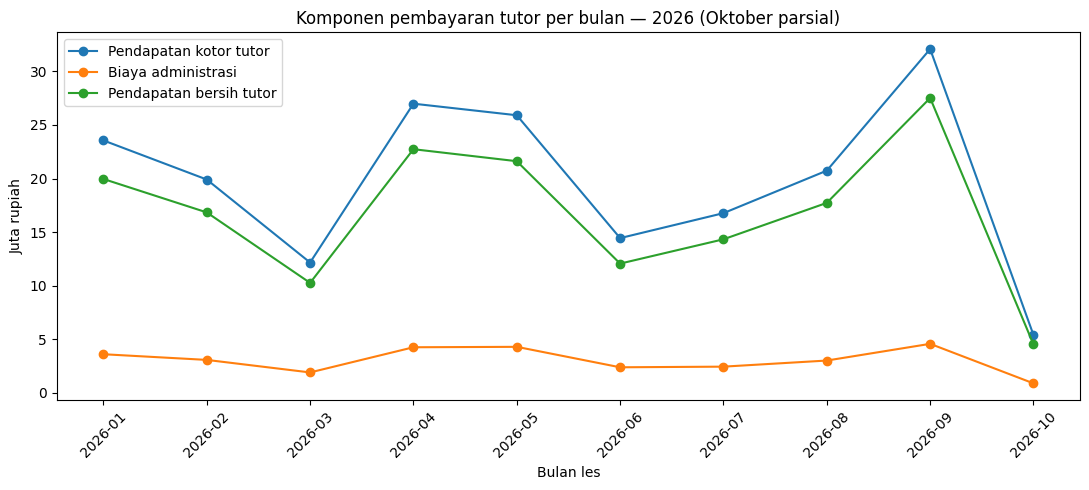

In [ ]:
monthly_actual = df_monthly.loc[df_monthly["source_year"].eq(2026)].sort_values("month_year")
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(monthly_actual["month_year"], monthly_actual["gross_pay_idr"] / 1_000_000,
        marker="o", label="Pendapatan kotor tutor")
ax.plot(monthly_actual["month_year"], monthly_actual["admin_fee_on_payroll_sessions_idr"] / 1_000_000,
        marker="o", label="Biaya administrasi")
ax.plot(monthly_actual["month_year"], monthly_actual["net_pay_idr"] / 1_000_000,
        marker="o", label="Pendapatan bersih tutor")
ax.set(title="Komponen pembayaran tutor per bulan — 2026 (Oktober parsial)",
       xlabel="Bulan les", ylabel="Juta rupiah")
ax.tick_params(axis="x", rotation=45)
ax.legend()
plt.tight_layout()
plt.show()

**Insight – Menjawab Pertanyaan 1 (Honor Tutor)**

- Honor kotor dan honor bersih bergerak sejalan dengan jumlah sesi, sedangkan biaya admin relatif stabil (Rp1,9–4,6 juta per bulan).
- **Pengeluaran honor tertinggi terjadi pada September 2026**: honor kotor Rp32,1 juta dan honor bersih Rp27,5 juta. Puncak lain terjadi pada April (Rp27,0 juta) dan Mei (Rp25,9 juta).
- **Pengeluaran terendah (bulan penuh) terjadi pada Maret 2026**: honor kotor Rp12,2 juta dan honor bersih Rp10,3 juta. Juni juga rendah (honor kotor Rp14,4 juta).
- Penurunan tajam pada Oktober (Rp5,4 juta) terjadi karena data baru tercatat hingga 21 Oktober, bukan karena aktivitas menurun.

### Aktivitas tutor: jumlah sesi dan perubahan aktivitas bulanan

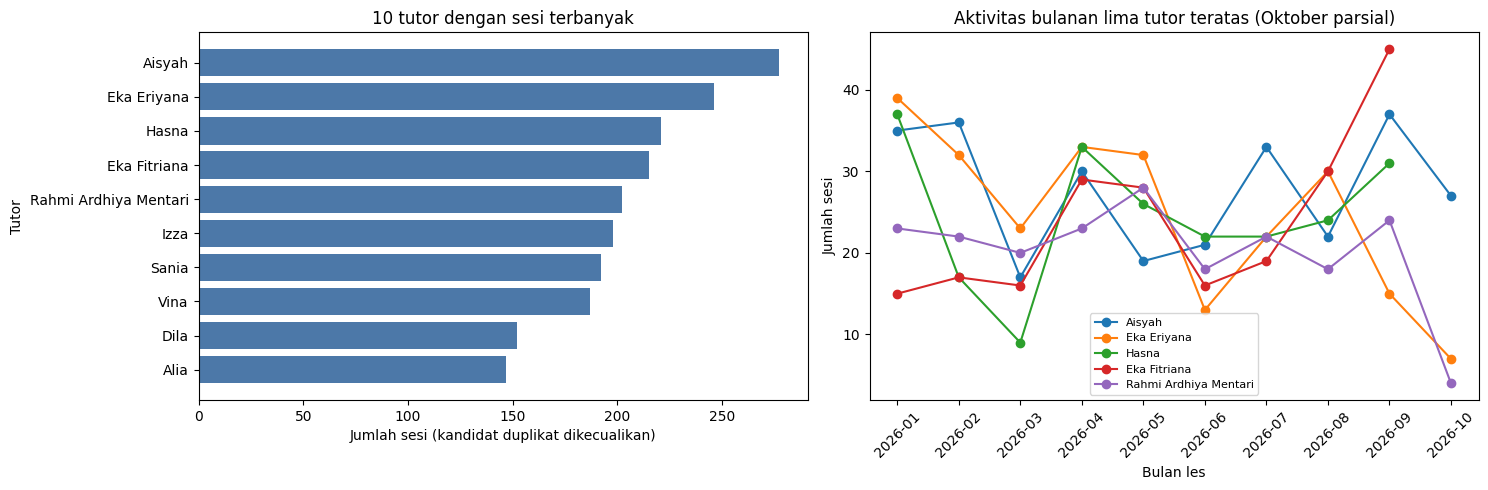

In [ ]:
tutor_actual = df_business.loc[~df_business["duplicate_candidate"]]
tutor_rank = tutor_actual.groupby(["tutor_id", "nama_tutor"], as_index=False).agg(
    sessions=("id", "nunique"), hours=("duration_hours", "sum")
).sort_values("sessions", ascending=False)
top_tutor_ids = tutor_rank.head(5)["tutor_id"].tolist()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
rank_plot = tutor_rank.head(10).sort_values("sessions")
axes[0].barh(rank_plot["nama_tutor"], rank_plot["sessions"], color="#4C78A8")
axes[0].set(title="10 tutor dengan sesi terbanyak",
            xlabel="Jumlah sesi (kandidat duplikat dikecualikan)", ylabel="Tutor")

tutor_trend = df_tutor_monthly.loc[
    df_tutor_monthly["source_year"].eq(2026)
    & df_tutor_monthly["tutor_id"].isin(top_tutor_ids)
]
for tutor_id in top_tutor_ids:
    line = tutor_trend.loc[tutor_trend["tutor_id"].eq(tutor_id)].sort_values("month_year")
    if not line.empty:
        axes[1].plot(line["month_year"], line["recorded_sessions"], marker="o",
                     label=line["nama_tutor"].iloc[0])
axes[1].set(title="Aktivitas bulanan lima tutor teratas (Oktober parsial)",
            xlabel="Bulan les", ylabel="Jumlah sesi")
axes[1].tick_params(axis="x", rotation=45)
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

**Insight – Menjawab Pertanyaan 2 (Aktivitas Tutor)**

- Delapan tutor teratas masing-masing menangani lebih dari 185 sesi, sehingga **beban mengajar terpusat pada kelompok inti tutor**.
- Tren lima tutor teratas fluktuatif: semuanya turun pada Maret dan Juni, lalu naik kembali. Eka Fitriana naik konsisten dari Juni hingga September (puncak 45 sesi), sedangkan Eka Eriyana turun tajam pada September (15 sesi).
- **Jumlah tutor aktif per bulan menurun** dari 18–19 tutor (Januari–Februari) menjadi 13–14 tutor (Agustus–September), padahal jumlah sesi meningkat. Rata-rata beban per tutor naik dari sekitar 19 sesi (Januari) menjadi sekitar 31 sesi (September).
- **Rekomendasi:** menambah atau mengaktifkan kembali tutor agar bimbel tidak terlalu bergantung pada beberapa tutor saja.

### Murid: komposisi jenjang, kelas, dan aktivitas bulanan

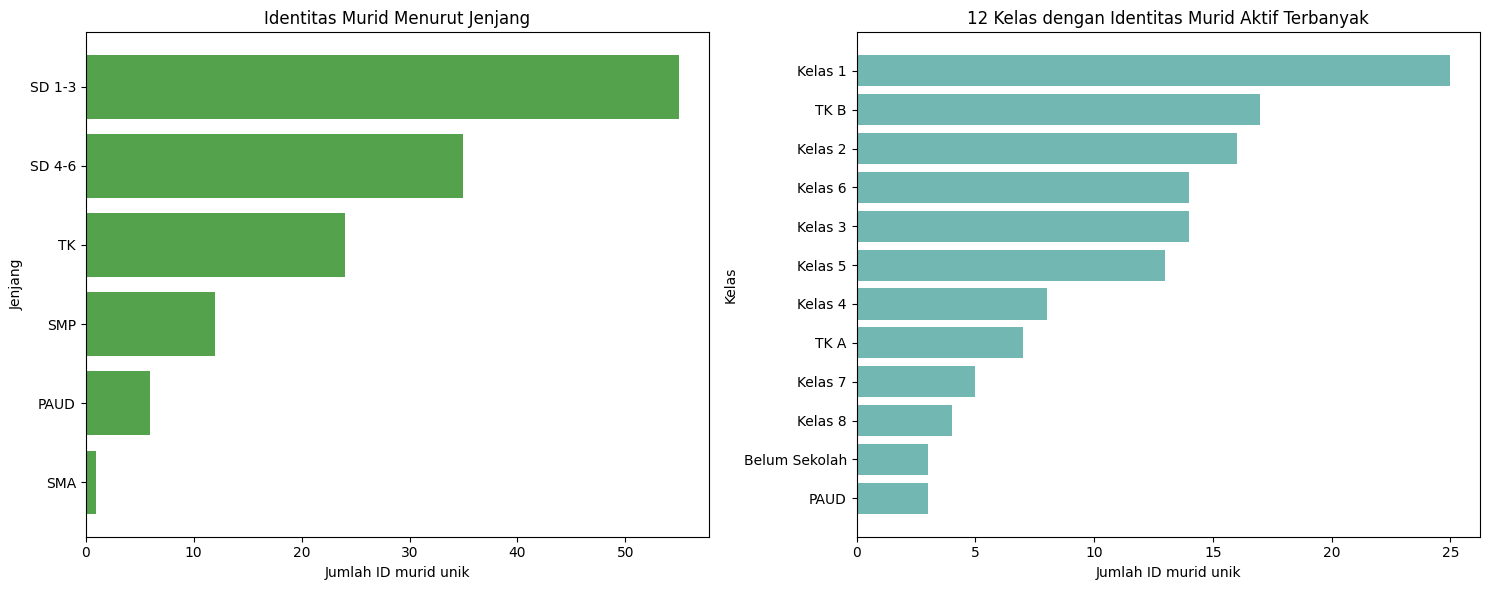

In [ ]:
level_counts = (
    df_student_composition
    .groupby("education_level")["active_student_identity_ids_2026"]
    .sum()
    .sort_values()
)

class_counts = (
    df_student_composition
    .groupby("kelas")["active_student_identity_ids_2026"]
    .sum()
    .sort_values(ascending=False)
    .head(12)
    .sort_values()
)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

axes[0].barh(level_counts.index, level_counts.values, color="#54A24B")
axes[0].set(
    title="Identitas Murid Menurut Jenjang",
    xlabel="Jumlah ID murid unik",
    ylabel="Jenjang",
)

axes[1].barh(class_counts.index.astype(str), class_counts.values, color="#72B7B2")
axes[1].set(
    title="12 Kelas dengan Identitas Murid Aktif Terbanyak",
    xlabel="Jumlah ID murid unik",
    ylabel="Kelas",
)

plt.tight_layout()
plt.show()

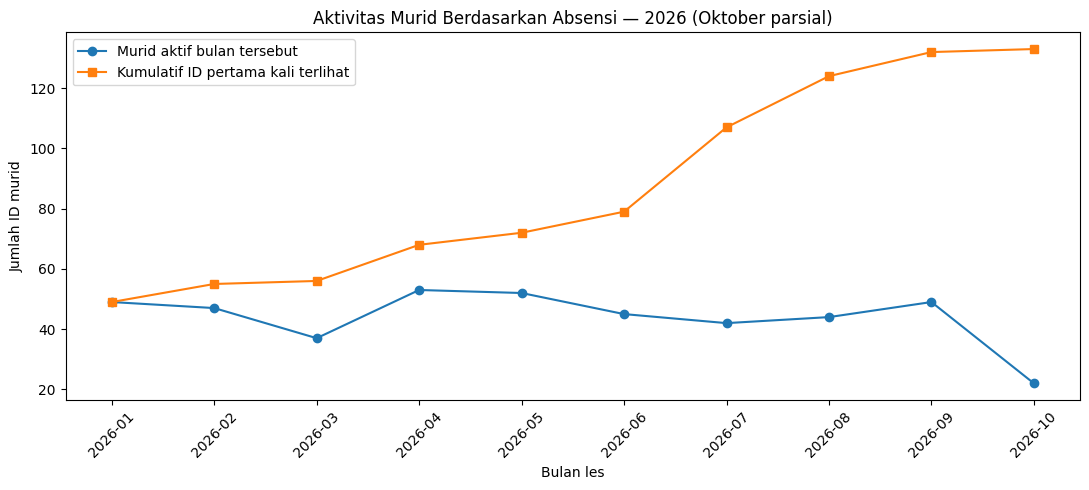

In [ ]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(
    df_student_monthly["month_year"],
    df_student_monthly["active_student_identity_ids"],
    marker="o",
    label="Murid aktif bulan tersebut",
)
ax.plot(
    df_student_monthly["month_year"],
    df_student_monthly["cumulative_first_seen_identity_estimate"],
    marker="s",
    label="Kumulatif ID pertama kali terlihat",
)
ax.set(
    title="Aktivitas Murid Berdasarkan Absensi — 2026 (Oktober parsial)",
    xlabel="Bulan les",
    ylabel="Jumlah ID murid",
)
ax.tick_params(axis="x", rotation=45)
ax.legend()
plt.tight_layout()
plt.show()

**Insight – Menjawab Pertanyaan 3 dan 4 (Murid)**

- **Pertanyaan 3:** SD 1-3 adalah segmen terbesar (55 ID aktif), diikuti SD 4-6 (35) dan TK (24). Per kelas, **Kelas 1** paling banyak (25 ID), diikuti TK B (17) dan Kelas 2 (16). Murid SMP dan SMA masih sangat sedikit.
- **Pertanyaan 4:** jumlah murid aktif per bulan stabil di kisaran **37–53 ID**, dengan titik terendah pada Maret (Oktober 22 ID karena datanya parsial).
- Kumulatif ID yang pertama kali terlihat naik dari 49 (Januari) menjadi 133 (Oktober). **Lonjakan terbesar terjadi pada Juli** (dari 79 menjadi 107), bertepatan dengan awal tahun ajaran baru. Karena murid mendapat ID baru saat naik kelas, sebagian "murid baru" ini kemungkinan adalah murid lama yang naik kelas.
- Bimbel dapat memanfaatkan awal tahun ajaran untuk promosi dan pendaftaran ulang murid.

### Mata pelajaran: mata pelajaran teratas, jenjang, dan tren bulanan

In [ ]:
top_subject_names = (
    df_subject_summary.head(8)["nama_mata_pelajaran"].tolist()
)

subject_by_level = (
    df_subject_activity[
        df_subject_activity["nama_mata_pelajaran"].isin(top_subject_names)
    ]
    .groupby(["nama_mata_pelajaran", "education_level"])["session_id"]
    .nunique()
    .unstack(fill_value=0)
)

subject_trend = (
    df_subject_monthly[
        df_subject_monthly["nama_mata_pelajaran"].isin(top_subject_names)
    ]
    .groupby(["nama_mata_pelajaran", "month_year"], as_index=False)["session_count"]
    .sum()
)

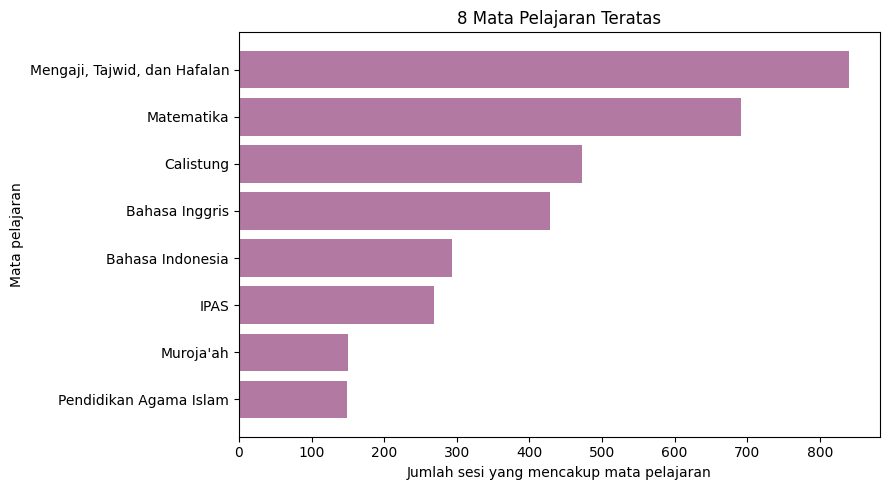

In [ ]:
subject_rank_plot = (
    df_subject_summary.head(8)
    .sort_values("session_count")
)

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(
    subject_rank_plot["nama_mata_pelajaran"],
    subject_rank_plot["session_count"],
    color="#B279A2",
)
ax.set(
    title="8 Mata Pelajaran Teratas",
    xlabel="Jumlah sesi yang mencakup mata pelajaran",
    ylabel="Mata pelajaran",
)
plt.tight_layout()
plt.show()

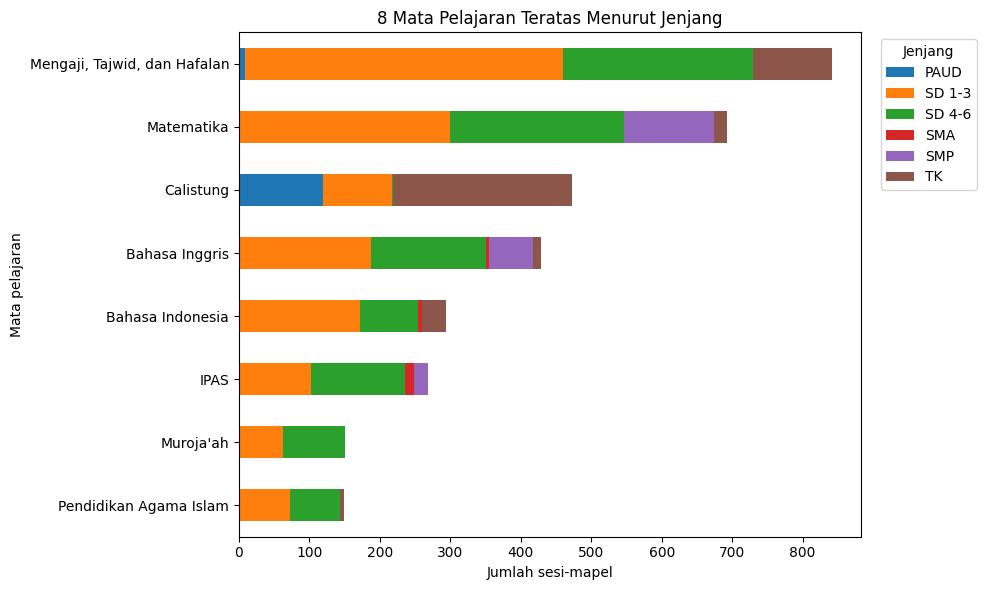

In [ ]:
level_order = subject_by_level.sum(axis=1).sort_values().index
subject_by_level_plot = subject_by_level.loc[level_order]

fig, ax = plt.subplots(figsize=(10, 6))
subject_by_level_plot.plot(kind="barh", stacked=True, ax=ax)
ax.set(
    title="8 Mata Pelajaran Teratas Menurut Jenjang",
    xlabel="Jumlah sesi-mapel",
    ylabel="Mata pelajaran",
)
ax.legend(title="Jenjang", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

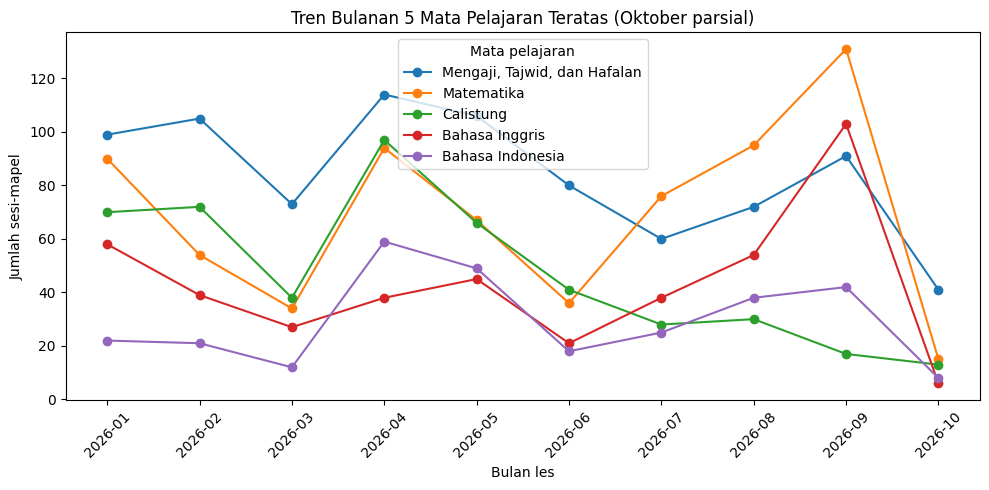

In [ ]:
top_5_subject_names = (
    df_subject_summary.head(5)["nama_mata_pelajaran"].tolist()
)

fig, ax = plt.subplots(figsize=(10, 5))
for subject_name in top_5_subject_names:
    line = (
        subject_trend[
            subject_trend["nama_mata_pelajaran"].eq(subject_name)
        ]
        .sort_values("month_year")
    )
    ax.plot(
        line["month_year"],
        line["session_count"],
        marker="o",
        label=subject_name,
    )

ax.set(
    title="Tren Bulanan 5 Mata Pelajaran Teratas (Oktober parsial)",
    xlabel="Bulan les",
    ylabel="Jumlah sesi-mapel",
)
ax.tick_params(axis="x", rotation=45)
ax.legend(title="Mata pelajaran")
plt.tight_layout()
plt.show()

**Insight – Menjawab Pertanyaan 5 (Mata Pelajaran)**

- **Mengaji, Tajwid, dan Hafalan** paling banyak diambil, terutama oleh murid SD 1-3, SD 4-6, dan TK.
- **Matematika** diambil di hampir semua jenjang (SD 1-3, SD 4-6, dan SMP); **Calistung** didominasi murid TK dan PAUD; **Bahasa Inggris** paling banyak diambil murid SD.
- Tren bulanan: **Matematika naik tajam sejak Juli dan mencapai puncak 131 sesi-mapel pada September**, melampaui Mengaji. Bahasa Inggris juga melonjak pada September (103). Sebaliknya, Calistung terus menurun sejak Mei, kemungkinan karena murid TK naik ke SD pada tahun ajaran baru.
- Semua mata pelajaran turun pada Maret dan Juni, sejalan dengan pola operasional bimbel.

### Operasional: jumlah sesi dan total jam mengajar per bulan

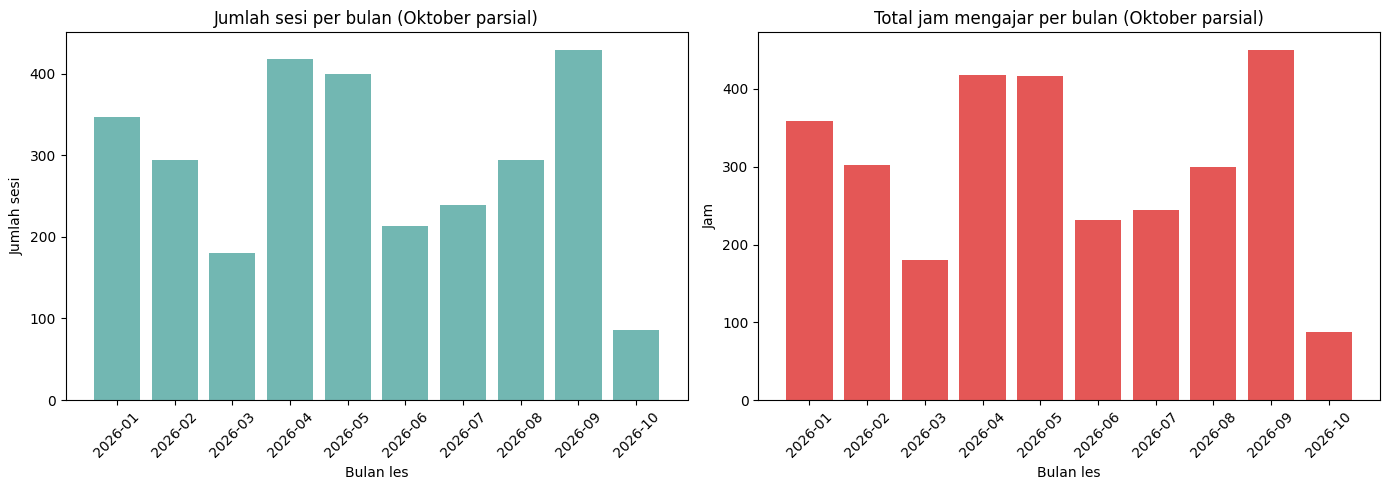

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].bar(monthly_actual["month_year"], monthly_actual["recorded_sessions"], color="#72B7B2")
axes[0].set(title="Jumlah sesi per bulan (Oktober parsial)", xlabel="Bulan les", ylabel="Jumlah sesi")
axes[0].tick_params(axis="x", rotation=45)
axes[1].bar(monthly_actual["month_year"], monthly_actual["recorded_hours"], color="#E45756")
axes[1].set(title="Total jam mengajar per bulan (Oktober parsial)", xlabel="Bulan les", ylabel="Jam")
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

**Insight – Menjawab Pertanyaan 6 (Operasional)**

- Jumlah sesi dan total jam mengajar bergerak hampir identik karena mayoritas sesi berdurasi 1 jam.
- **Puncak** terjadi pada April (418 sesi), Mei (399 sesi), dan September (429 sesi; 450 jam). **Titik terendah** terjadi pada Maret (180 sesi) dan Juni (213 sesi).
- Pola ini kemungkinan bersifat musiman: penurunan Maret bertepatan dengan Ramadan dan libur Idulfitri 2026, penurunan Juni–Juli dengan libur kenaikan kelas, sedangkan puncak April–Mei dan September bertepatan dengan periode ujian sekolah. Dugaan ini perlu dikonfirmasi dengan kalender sekolah.
- Oktober hanya mencakup data hingga 21 Oktober sehingga belum dapat dibandingkan dengan bulan lain.

## Susunan Baris Data Untuk Tim AE

In [ ]:
CONFIG = {"durationOutlierMinutes": LONG_DURATION_MINUTES, "lateStartAfter": LATE_START_AFTER}
ai_rows = []
ai_excluded = []
for _, row in df_clean.iterrows():
    reasons = []
    if int(row["source_year"]) != 2026 or int(row["year"]) != 2026:
        reasons.append("not_actual_2026_session")
    if bool(row["source_year_date_mismatch"]):
        reasons.append("source_year_date_mismatch")
    if bool(row["duplicate_candidate"]):
        reasons.append("duplicate_candidate_needs_review")
    if bool(row["duration_review"]):
        reasons.append("duration_above_180_needs_review")
    if bool(row["late_start_review"]):
        reasons.append("start_after_21_00_needs_review")
    if bool(row["short_duration_review"]):
        reasons.append("duration_below_30_needs_review")
    if bool(row["early_start_review"]):
        reasons.append("start_before_07_00_needs_review")

    subject_ids = json.loads(row["subject_ids"])
    if not 1 <= len(subject_ids) <= 3:
        reasons.append("subject_count_outside_1_to_3")
    if not row["start_time"]:
        start_time_value = None
    else:
        start_time_value = row["start_time"]

    target = {
        "id": row["id"],
        "tutor_id": row["tutor_id"],
        "student_id": row["student_id"],
        "subject_ids": sorted(subject_ids),
        "lesson_date": row["lesson_date"],
        "start_time": start_time_value,
        "duration_minutes": int(row["duration_minutes"]),
        "submitted_at": row["submitted_at"],
    }
    if reasons:
        ai_excluded.append({"session_id": row["id"], "reason": "|".join(sorted(set(reasons)))})
        if int(row["source_year"]) == 2026:
            audit_rows.append({
                "source_row": int(row["source_row"]),
                "session_id": row["id"],
                "action": "excluded_from_ai_clean_base",
                "reason": "|".join(sorted(set(reasons))),
            })
    else:
        ai_rows.append({"target": target, "config": CONFIG.copy()})

df_audit = pd.DataFrame(audit_rows, columns=["source_row", "session_id", "action", "reason"])
print("Basis clean JSONL untuk tim AE:", len(ai_rows), "baris; dikecualikan:", len(ai_excluded))
if ai_excluded:
    ai_exclusion_summary = (
        pd.Series([item["reason"] for item in ai_excluded])
        .value_counts().rename_axis("alasan").to_frame("jumlah")
    )
    display(ai_exclusion_summary)

Basis clean JSONL untuk tim AE: 2886 baris; dikecualikan: 2090


,jumlah
alasan,
not_actual_2026_session,2023
duplicate_candidate_needs_review,33
duplicate_candidate_needs_review|not_actual_2026_session,8
subject_count_outside_1_to_3,7
not_actual_2026_session|subject_count_outside_1_to_3,6
not_actual_2026_session|source_year_date_mismatch,4
duration_below_30_needs_review,4
duration_below_30_needs_review|not_actual_2026_session,2
not_actual_2026_session|start_before_07_00_needs_review,1


**Insight – Data untuk Tim AE**

- Basis data bersih untuk tim AE berisi **2.886 sesi** dalam format JSONL (target + config) tanpa data pribadi.
- Dari 2.090 sesi yang dikecualikan, 2.044 adalah sesi non-aktual (data 2025 atau tahun yang tidak konsisten). Dari sesi aktual 2026 hanya **46 sesi** yang dikecualikan: 33 salinan duplikat, 7 sesi dengan lebih dari 3 mata pelajaran, 4 sesi < 30 menit, 1 sesi dimulai sebelum 07.00, dan 1 sesi > 180 menit.
- Sesi 30–59 menit kini ikut dimasukkan karena aturan honornya sudah ditetapkan. Bersama perbaikan parser durasi, data untuk tim AE bertambah dari 2.712 menjadi 2.886 sesi.

## Validasi Akhir yang Dijalankan Ulang

In [ ]:
assert len(df_clean) + len(df_exceptions) == len(df_absensi_raw), "Jumlah baris tidak terjelaskan."
assert df_clean["id"].is_unique, "Session ID pada cleaned tidak unik."
assert df_clean["id"].map(compact_uuid).notna().all(), "Session ID tidak valid."
assert df_clean["tutor_id"].map(compact_uuid).notna().all()
assert df_clean["student_id"].map(compact_uuid).notna().all()
assert all(all(compact_uuid(x) for x in json.loads(ids)) for ids in df_clean["subject_ids"])
assert df_clean["duration_minutes"].gt(0).all()
assert df_clean["lesson_date"].map(lambda value: bool(re.fullmatch(r"\d{4}-\d{2}-\d{2}", value))).all()
permitted_nulls = {"start_time", "billable_hours", "gross_pay_idr", "net_pay_idr"}
nulls_to_validate = df_clean.drop(columns=list(permitted_nulls), errors="ignore").isna().sum()
assert (nulls_to_validate == 0).all(), f"Null pada kolom wajib ditemukan: {nulls_to_validate[nulls_to_validate.gt(0)].to_dict()}"

jsonl_ids = []
for line_number, item in enumerate(ai_rows, start=1):
    line = json.dumps(item, ensure_ascii=False)
    assert set(item) == {"target", "config"}, f"Top-level JSON salah pada baris {line_number}."
    target, config = item["target"], item["config"]
    assert set(target) == {"id", "tutor_id", "student_id", "subject_ids", "lesson_date", "start_time", "duration_minutes", "submitted_at"}
    assert set(config) == {"durationOutlierMinutes", "lateStartAfter"}
    assert dashed_uuid(target["id"]) == target["id"]
    assert compact_uuid(target["tutor_id"]) in tutor_by_id
    assert compact_uuid(target["student_id"]) in student_by_id
    assert isinstance(target["subject_ids"], list) and 1 <= len(target["subject_ids"]) <= 3
    assert target["subject_ids"] == sorted(target["subject_ids"])
    assert all(compact_uuid(subject_id) in subject_by_id for subject_id in target["subject_ids"])
    assert date.fromisoformat(target["lesson_date"]).year == 2026
    assert target["start_time"] is None or re.fullmatch(r"(?:[01]\d|2[0-3]):[0-5]\d", target["start_time"])
    assert isinstance(target["duration_minutes"], int) and target["duration_minutes"] > 0
    assert target["duration_minutes"] <= CONFIG["durationOutlierMinutes"]
    assert target["start_time"] is None or target["start_time"] <= CONFIG["lateStartAfter"]
    parsed_timestamp = datetime.fromisoformat(target["submitted_at"].replace("Z", "+00:00"))
    assert parsed_timestamp.tzinfo is not None and parsed_timestamp.utcoffset() == timedelta(0)
    assert not any(token in line.casefold() for token in ["nama_tutor", "nama_murid", "asal_sekolah", "kelas", "dokumentasi"])
    jsonl_ids.append(target["id"])

assert len(jsonl_ids) == len(set(jsonl_ids)), "ID sesi duplikat dalam JSONL."
assert len(jsonl_ids) == len(ai_rows), "Jumlah baris JSONL tidak cocok."

### Validasi ulang tarif, jam tagihan, biaya admin, neto, dan rekap per bulan

In [ ]:
eligible = df_actual_payroll
for _, row in eligible.iterrows():
    expected_hours = billable_hours(row["duration_minutes"])
    expected_gross = round(float(row["tariff_hourly_rate_idr"]) * expected_hours)
    expected_admin = admin_fee(row["duration_minutes"])
    assert abs(float(row["billable_hours"]) - expected_hours) < 1e-9
    assert int(row["gross_pay_idr"]) == expected_gross
    assert int(row["admin_fee_idr"]) == expected_admin
    assert int(row["net_pay_idr"]) == expected_gross - expected_admin
assert np.allclose(
    eligible["gross_pay_idr"] - eligible["admin_fee_idr"],
    eligible["net_pay_idr"],
    equal_nan=False,
)
for _, monthly_row in df_monthly.loc[df_monthly["source_year"].eq(2026)].iterrows():
    month_rows = df_business.loc[df_business["month_year"].eq(monthly_row["month_year"])]
    month_payroll = month_rows.loc[month_rows["payroll_eligible"]]
    assert int(monthly_row["recorded_sessions"]) == len(month_rows)
    assert int(monthly_row["payroll_eligible_sessions"]) == len(month_payroll)
    assert int(monthly_row["gross_pay_idr"]) == int(month_payroll["gross_pay_idr"].sum())
    assert int(monthly_row["admin_fee_on_payroll_sessions_idr"]) == int(month_payroll["admin_fee_idr"].sum())
    assert int(monthly_row["net_pay_idr"]) == int(month_payroll["net_pay_idr"].sum())
assert int(df_student_composition["master_student_identity_ids"].sum()) == len(df_murid)
assert int(df_student_composition["active_student_identity_ids_2026"].sum()) == len(active_student_ids)
print("\nVALIDASI LULUS")
print(f"Sumber: {len(df_absensi_raw):,}; cleaned: {len(df_clean):,}; dikeluarkan: {len(df_exceptions):,}")
print(f"JSONL clean-only: {len(ai_rows):,} baris; format target+config; tanpa PII")
print("Relasi master, UUID, tanggal, durasi, null, dan hitung neto berhasil diperiksa.")


VALIDASI LULUS
Sumber: 5,035; cleaned: 4,976; dikeluarkan: 59
JSONL clean-only: 2,886 baris; format target+config; tanpa PII
Relasi master, UUID, tanggal, durasi, null, dan hitung neto berhasil diperiksa.


**Insight – Validasi Akhir**

- **Seluruh validasi lulus:** jumlah baris terjelaskan (4.976 bersih + 59 dikeluarkan = 5.035), ID sesi unik dan valid, relasi ke tabel master terpenuhi, format tanggal dan durasi benar, serta tidak ada nilai kosong pada kolom wajib.
- Setiap baris JSONL sesuai format target + config, memiliki 1–3 mata pelajaran, waktu submit dalam UTC, dan tidak memuat data pribadi.
- Honor kotor, biaya admin, dan honor bersih setiap sesi serta rekap bulanan dihitung ulang dan cocok dengan aturan bisnis.

## Analisis Lanjutan

### Klasifikasi Potensi Ketidakaktifan Murid

In [ ]:
df_model = df_business.copy()
df_model["month_start"] = pd.to_datetime(df_model["month_year"] + "-01")
month_periods = pd.period_range("2026-01", "2026-09", freq="M")
classification_metrics = {}
classification_confusion = None
classification_note = "Belum tersedia."

student_month = df_model.groupby(["student_id", "month_start"]).size().to_dict()
education_by_student = df_model.groupby("student_id")["education_level"].agg(
    lambda values: values.mode().iloc[0] if not values.mode().empty else "tidak_diketahui"
).to_dict()

classification_rows = []
for student_id in df_model["student_id"].unique():
    for index, period in enumerate(month_periods[:-1]):
        current_month = period.to_timestamp()
        next_month = (period + 1).to_timestamp()
        current_count = int(student_month.get((student_id, current_month), 0))
        if current_count == 0:
            continue
        previous_count = (
            int(student_month.get((student_id, (period - 1).to_timestamp()), 0))
            if index >= 1 else 0
        )
        last3_counts = [
            int(student_month.get((student_id, (period - lag).to_timestamp()), 0))
            if index >= lag else 0
            for lag in [0, 1, 2]
        ]
        classification_rows.append({
            "observation_month": str(period),
            "month_index": index + 1,
            "sessions_t": current_count,
            "sessions_previous_month": previous_count,
            "sessions_last3": sum(last3_counts),
            "active_months_last3": sum(value > 0 for value in last3_counts),
            "education_level": education_by_student.get(student_id, "tidak_diketahui"),
            "inactive_next_month": int(student_month.get((student_id, next_month), 0) == 0),
        })

df_classification = pd.DataFrame(classification_rows)
if not df_classification.empty:
    train_c = df_classification[
        df_classification["observation_month"].between("2026-01", "2026-04")
    ]
    test_c = df_classification[
        df_classification["observation_month"].between("2026-06", "2026-08")
    ]
    features_c = [
        "month_index", "sessions_t", "sessions_previous_month", "sessions_last3",
        "active_months_last3", "education_level",
    ]
    if (
        len(train_c) >= 20
        and len(test_c) >= 20
        and train_c["inactive_next_month"].nunique() == 2
    ):
        numeric_c = features_c[:-1]
        prep_c = ColumnTransformer([
            ("num", Pipeline([
                ("impute", SimpleImputer(strategy="median")),
                ("scale", StandardScaler()),
            ]), numeric_c),
            ("education", OneHotEncoder(handle_unknown="ignore"), ["education_level"]),
        ])
        baseline_c = Pipeline([
            ("prep", prep_c), ("model", DummyClassifier(strategy="most_frequent")),
        ])
        model_c = Pipeline([
            ("prep", prep_c),
            ("model", LogisticRegression(
                max_iter=1500, class_weight="balanced", random_state=42,
            )),
        ])
        baseline_c.fit(train_c[features_c], train_c["inactive_next_month"])
        model_c.fit(train_c[features_c], train_c["inactive_next_month"])

        actual_c = test_c["inactive_next_month"].to_numpy()
        prediction_baseline = baseline_c.predict(test_c[features_c])
        prediction_model = model_c.predict(test_c[features_c])
        classification_confusion = confusion_matrix(
            actual_c, prediction_model, labels=[0, 1],
        )
        for name, prediction in [
            ("baseline_most_frequent", prediction_baseline),
            ("logistic_regression", prediction_model),
        ]:
            classification_metrics[name] = {
                "accuracy": float(accuracy_score(actual_c, prediction)),
                "precision_macro": float(precision_score(
                    actual_c, prediction, average="macro", zero_division=0,
                )),
                "recall_macro": float(recall_score(
                    actual_c, prediction, average="macro", zero_division=0,
                )),
                "f1_macro": float(f1_score(
                    actual_c, prediction, average="macro", zero_division=0,
                )),
            }
        classification_note = (
            f"Evaluasi temporal: train Jan–Apr ({len(train_c)} observasi), "
            f"uji Jun–Agu ({len(test_c)} observasi); Mei menjadi jeda waktu."
        )
    else:
        classification_note = (
            "Data belum cukup atau kelas target pada train hanya satu; "
            "metrik klasifikasi tidak dihitung."
        )
else:
    classification_note = "Belum cukup data untuk membentuk target bulanan."

print("Catatan target:", classification_note)
if classification_metrics:
    display(pd.DataFrame(classification_metrics).T)

Catatan target: Evaluasi temporal: train Jan–Apr (186 observasi), uji Jun–Agu (131 observasi); Mei menjadi jeda waktu.


,accuracy,precision_macro,recall_macro,f1_macro
baseline_most_frequent,0.587786,0.293893,0.50000,0.370192
logistic_regression,0.458015,0.480045,0.48088,0.456876


**Insight – Menjawab Pertanyaan 7 (Klasifikasi)**

- Model logistic regression dilatih pada Januari–April (186 observasi) dan diuji pada Juni–Agustus (131 observasi); Mei dijadikan jeda agar tidak ada kebocoran data.
- **Akurasi model (45,8%) lebih rendah daripada baseline** yang selalu menebak kelas terbanyak (58,8%). F1-macro model sedikit lebih baik (0,457 vs 0,370), tetapi masih mendekati tebakan acak.
- **Jawaban pertanyaan 7:** dengan fitur saat ini (jumlah sesi bulan ini, bulan lalu, 3 bulan terakhir, dan jenjang), pola sesi **belum dapat memprediksi secara andal** apakah murid akan tidak aktif pada bulan berikutnya.
- Salah satu penyebabnya: periode uji mencakup awal tahun ajaran (Juli), ketika murid yang naik kelas mendapat ID baru sehingga ID lamanya terlihat "tidak aktif". Perbaikan yang disarankan: menghubungkan ID murid yang sama antar kelas, menambah data historis, serta fitur kalender sekolah (libur dan ujian).

### Forecasting Jumlah Sesi Bulanan

In [ ]:
monthly_counts = df_business.groupby("month_year")["id"].nunique()
forecast_values = [
    float(monthly_counts.get(f"2026-{month:02d}", 0))
    for month in range(1, 10)
]
forecast_rows = []
for index in range(6, len(forecast_values)):
    history = forecast_values[:index]
    linear_coefficients = np.polyfit(np.arange(len(history)), history, 1)
    forecast_rows.append({
        "month": f"2026-{index + 1:02d}",
        "actual": forecast_values[index],
        "naive": history[-1],
        "moving_average_3": float(np.mean(history[-3:])),
        "linear_trend": float(np.polyval(linear_coefficients, len(history))),
    })

df_forecast = pd.DataFrame(forecast_rows)
forecast_metrics = {}
forecast_model = "belum tersedia"
forecast_for_next = np.nan
if not df_forecast.empty:
    for name in ["naive", "moving_average_3", "linear_trend"]:
        actual = df_forecast["actual"].to_numpy()
        prediction = df_forecast[name].to_numpy()
        nonzero = actual != 0
        forecast_metrics[name] = {
            "MAE": float(mean_absolute_error(actual, prediction)),
            "RMSE": float(np.sqrt(mean_squared_error(actual, prediction))),
            "MAPE_nonzero_pct": (
                float(np.mean(np.abs(
                    (actual[nonzero] - prediction[nonzero]) / actual[nonzero]
                )) * 100)
                if nonzero.any() else float("nan")
            ),
        }

    forecast_model = min(
        forecast_metrics, key=lambda name: forecast_metrics[name]["MAE"]
    )
    if forecast_model == "naive":
        forecast_for_next = forecast_values[-1]
    elif forecast_model == "moving_average_3":
        forecast_october = float(np.mean(forecast_values[-3:]))
        forecast_for_next = float(np.mean([
            forecast_values[-2], forecast_values[-1], forecast_october,
        ]))
    else:
        coefficients = np.polyfit(np.arange(len(forecast_values)), forecast_values, 1)
        forecast_for_next = float(np.polyval(coefficients, len(forecast_values) + 1))

forecast_note = (
    f"Walk-forward satu langkah pada bulan penuh Jan–Sep; metode dengan MAE terendah: {forecast_model}. "
    "Oktober parsial tidak dipakai sebagai histori model."
)
print(forecast_note)
if forecast_metrics:
    display(pd.DataFrame(forecast_metrics).T)
    print(f"Estimasi indikatif jumlah sesi November 2026: {forecast_for_next:.1f}")

Walk-forward satu langkah pada bulan penuh Jan–Sep; metode dengan MAE terendah: naive. Oktober parsial tidak dipakai sebagai histori model.


,MAE,RMSE,MAPE_nonzero_pct
naive,72.000000,85.490740,20.351559
moving_average_3,98.333333,120.433015,29.734865
linear_trend,84.230952,100.817466,24.402339


Estimasi indikatif jumlah sesi November 2026: 429.0


**Insight – Menjawab Pertanyaan 8 (Forecasting)**

- Tiga metode sederhana diuji secara walk-forward pada Juli–September. **Metode naive** (bulan depan = bulan terakhir) paling akurat dengan MAE 72 sesi (MAPE 20,4%), lebih baik daripada tren linier (MAE 84,2) dan rata-rata 3 bulan (MAE 98,3).
- **Prediksi jumlah sesi November 2026: sekitar 429 sesi**, sama dengan jumlah sesi September (bulan penuh terakhir).
- Evaluasi hanya memakai 3 bulan uji sehingga hasilnya bersifat indikatif. Oktober tidak dipakai karena datanya belum lengkap.

### Clustering Aktivitas Tutor

In [ ]:
tutors_2026 = sorted(df_model["tutor_id"].dropna().unique())
cluster_scores = {}
cluster_plot_data = pd.DataFrame()
cluster_note = "Belum tersedia."

if len(tutors_2026) >= 4:
    tutor_activity = df_model.groupby("tutor_id").agg(
        total_sessions=("id", "nunique"),
        total_hours=("duration_hours", "sum"),
        unique_students=("student_id", "nunique"),
        active_months=("month_year", "nunique"),
    ).reindex(tutors_2026).fillna(0)
    tutor_activity["sessions_per_active_month"] = (
        tutor_activity["total_sessions"]
        / tutor_activity["active_months"].replace(0, np.nan)
    )
    tutor_activity = tutor_activity.fillna(0)
    scaled_activity = StandardScaler().fit_transform(tutor_activity)

    for cluster_count in range(2, min(5, len(tutors_2026))):
        candidate_labels = KMeans(
            n_clusters=cluster_count, random_state=42, n_init=20,
        ).fit_predict(scaled_activity)
        if len(set(candidate_labels)) > 1:
            cluster_scores[cluster_count] = float(
                silhouette_score(scaled_activity, candidate_labels)
            )

    if cluster_scores:
        best_k = max(cluster_scores, key=cluster_scores.get)
        labels = KMeans(
            n_clusters=best_k, random_state=42, n_init=20,
        ).fit_predict(scaled_activity)
        cluster_plot_data = tutor_activity.reset_index().assign(cluster=labels)
        cluster_note = (
            f"KMeans deskriptif pada {len(tutors_2026)} tutor; "
            f"k={best_k} dipilih berdasarkan silhouette."
        )
else:
    cluster_note = "Jumlah tutor belum cukup untuk membentuk cluster."

print(cluster_note)
if cluster_scores:
    display(pd.DataFrame([
        {"jumlah_cluster": count, "silhouette": score}
        for count, score in cluster_scores.items()
    ]))
    display(cluster_plot_data.groupby("cluster")[
        ["total_sessions", "total_hours", "unique_students", "active_months"]
    ].mean().round(2))

KMeans deskriptif pada 26 tutor; k=3 dipilih berdasarkan silhouette.


,jumlah_cluster,silhouette
0,2,0.458737
1,3,0.478062
2,4,0.340306


,total_sessions,total_hours,unique_students,active_months
cluster,,,,
0,54.56,54.79,4.19,4.44
1,208.22,217.79,12.22,8.56
2,152.00,152.50,14.00,2.00


**Insight – Menjawab Pertanyaan 9 (Clustering)**

- 26 tutor aktif 2026 dikelompokkan menjadi **3 cluster** (silhouette 0,48, pemisahan cukup baik):
  - **Cluster 0 – aktivitas rendah (16 tutor):** rata-rata 54,6 sesi, 4 murid, aktif 4,4 bulan.
  - **Cluster 1 – tutor inti (9 tutor):** rata-rata 208 sesi, 12 murid, aktif 8,6 bulan.
  - **Cluster 2 – tutor intensif (1 tutor):** 152 sesi dengan 14 murid hanya dalam 2 bulan (Agustus–September).
- **Jawaban pertanyaan 9:** tutor dapat dikelompokkan dengan jelas berdasarkan aktivitasnya. Sebagian besar tutor (16 dari 26) beraktivitas rendah, sedangkan 9 tutor inti menanggung sebagian besar sesi.

### Hasil Modelling

#### Visualisasi Confusion Matrix Klasifikasi

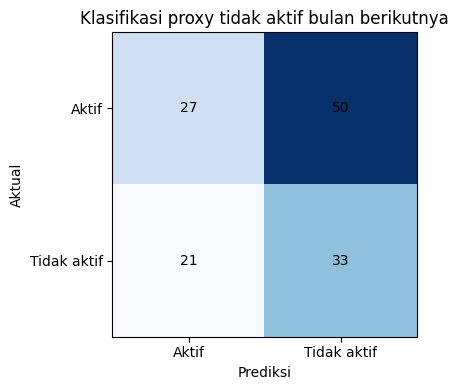

In [ ]:
if classification_confusion is None:
    print("Confusion matrix belum tersedia karena data evaluasi belum cukup.")
else:
    fig, ax = plt.subplots(figsize=(5, 4))
    ax.imshow(classification_confusion, cmap="Blues")
    ax.set(
        title="Klasifikasi proxy tidak aktif bulan berikutnya",
        xlabel="Prediksi", ylabel="Aktual",
        xticks=[0, 1], yticks=[0, 1],
        xticklabels=["Aktif", "Tidak aktif"],
        yticklabels=["Aktif", "Tidak aktif"],
    )
    for (row_index, col_index), value in np.ndenumerate(classification_confusion):
        ax.text(col_index, row_index, str(value), ha="center", va="center")
    plt.tight_layout()
    plt.show()

**Insight – Confusion Matrix**

- Dari 54 murid yang benar-benar tidak aktif pada bulan berikutnya, model mengenali **33 murid (61%)**, tetapi juga salah menandai **50 dari 77 murid aktif** sebagai tidak aktif.
- Artinya model terlalu sering memprediksi "tidak aktif" (precision kelas tidak aktif hanya 40%), sehingga belum layak dipakai untuk menentukan murid yang perlu ditindaklanjuti.

#### Hasil Forecast Sesi Sebulan

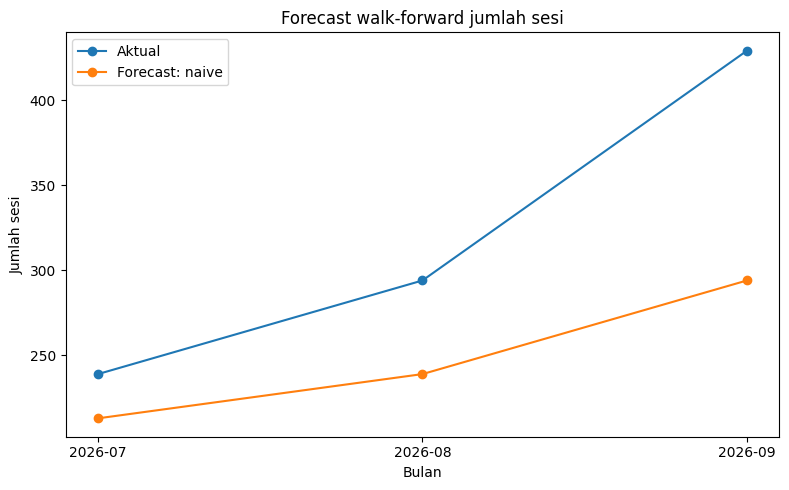

In [ ]:
if df_forecast.empty:
    print("Grafik forecast belum tersedia karena histori uji tidak cukup.")
else:
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.plot(df_forecast["month"], df_forecast["actual"], marker="o", label="Aktual")
    ax.plot(
        df_forecast["month"], df_forecast[forecast_model],
        marker="o", label=f"Forecast: {forecast_model}",
    )
    ax.set(title="Forecast walk-forward jumlah sesi",
           xlabel="Bulan", ylabel="Jumlah sesi")
    ax.legend()
    plt.tight_layout()
    plt.show()

**Insight – Hasil Forecast**

- Prediksi metode naive selalu berada di bawah nilai aktual karena jumlah sesi terus naik dari Juli (239) hingga September (429). Selisih terbesar terjadi pada September (135 sesi).
- Metode naive lambat menangkap tren naik. Jika tren kenaikan berlanjut, jumlah sesi November bisa lebih tinggi daripada prediksi 429 sesi.

#### Hasil Clustering Tutor

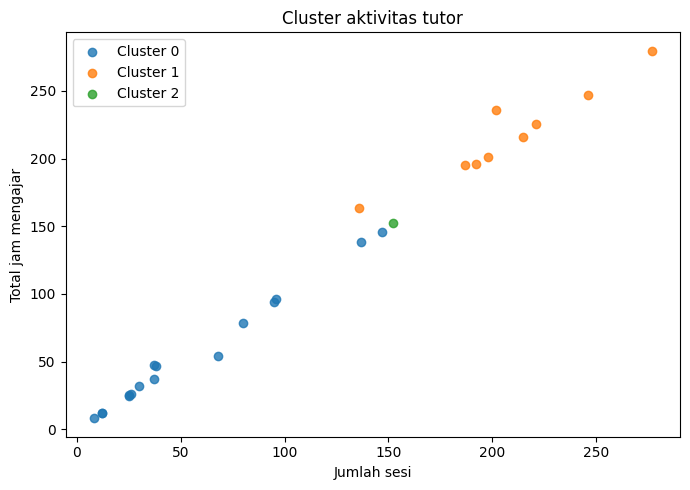

In [ ]:
if cluster_plot_data.empty:
    print("Grafik cluster belum tersedia karena jumlah tutor tidak cukup.")
else:
    fig, ax = plt.subplots(figsize=(7, 5))
    for cluster_id, group in cluster_plot_data.groupby("cluster"):
        ax.scatter(
            group["total_sessions"], group["total_hours"],
            label=f"Cluster {cluster_id}", alpha=0.8,
        )
    ax.set(title="Cluster aktivitas tutor",
           xlabel="Jumlah sesi", ylabel="Total jam mengajar")
    ax.legend()
    plt.tight_layout()
    plt.show()

**Insight – Hasil Clustering Tutor**

- Jumlah sesi dan total jam mengajar hampir sebanding lurus, sehingga cluster terutama dibedakan oleh volume aktivitas dan lamanya tutor aktif.
- Tutor inti (cluster 1) berada di kanan atas grafik (sekitar 135–277 sesi), tutor aktivitas rendah (cluster 0) tersebar di bawah 150 sesi, dan satu tutor intensif (cluster 2) terpisah karena aktivitasnya sangat padat dalam waktu singkat.
- **Rekomendasi:** memprioritaskan retensi tutor inti dan meningkatkan jadwal tutor beraktivitas rendah agar beban mengajar lebih merata.

## Ekspor Dataset

In [ ]:
df_clean_final = df_clean.copy().reset_index(drop=True)
if not df_clean_final["id"].is_unique:
    raise ValueError("ID sesi pada data bersih tidak unik.")

df_features_final = df_clean_final.copy()
df_features_final["subject_count"] = df_features_final["subject_ids"].map(
    lambda value: len(json.loads(value))
)
ordered = df_features_final.sort_values(
    ["lesson_date", "start_time", "id"], na_position="last"
).copy()
ordered["tutor_sessions_to_date"] = ordered.groupby("tutor_id").cumcount() + 1
ordered["student_sessions_to_date"] = ordered.groupby("student_id").cumcount() + 1
df_features_final["tutor_sessions_to_date"] = ordered["tutor_sessions_to_date"].sort_index()
df_features_final["student_sessions_to_date"] = ordered["student_sessions_to_date"].sort_index()
df_features_final["month_sessions_for_tutor"] = (
    df_features_final.groupby(["tutor_id", "month_year"])["id"].transform("count")
)
df_features_final["month_sessions_for_student"] = (
    df_features_final.groupby(["student_id", "month_year"])["id"].transform("count")
)

df_features_final["nama_tutor"] = df_features_final["tutor_id"].map(
    lambda value: tutor_by_id.get(compact_uuid(value))
)
student_records = df_features_final["student_id"].map(
    lambda value: student_by_id.get(compact_uuid(value), {})
)
df_features_final["nama_murid"] = student_records.map(
    lambda record: record.get("nama_murid")
)
df_features_final["asal_sekolah"] = student_records.map(
    lambda record: record.get("asal_sekolah")
)
df_features_final["nama_mata_pelajaran"] = df_features_final["subject_ids"].map(
    lambda value: json.dumps(
        [subject_by_id.get(compact_uuid(subject_id))
         for subject_id in json.loads(value)],
        ensure_ascii=False,
    )
)

CLEAN_EXPORT_COLUMNS = [
    "id", "tutor_id", "nama_tutor", "student_id", "nama_murid", "asal_sekolah",
    "subject_ids", "nama_mata_pelajaran", "lesson_date", "source_year", "year",
    "month", "month_year", "day_of_week", "start_time", "duration_minutes",
    "duration_hours", "submitted_at", "duration_normalized", "education_level",
    "tariff_hourly_rate_idr", "billable_hours", "gross_pay_idr", "admin_fee_idr",
    "net_pay_idr", "subject_count", "tutor_sessions_to_date",
    "student_sessions_to_date", "month_sessions_for_tutor",
    "month_sessions_for_student",
]
clean_candidates = df_features_final[CLEAN_EXPORT_COLUMNS].copy()
null_or_blank = clean_candidates.isnull().any(axis=1)
for column in clean_candidates.columns:
    null_or_blank |= clean_candidates[column].astype("string").str.strip().eq("").fillna(False)
df_clean_export = clean_candidates.loc[~null_or_blank].reset_index(drop=True)
export_rows_excluded = int(null_or_blank.sum())
export_short_rows_excluded = int(
    (null_or_blank & df_features_final["duration_minutes"].lt(60)).sum()
)

FEATURE_TARGET_COLUMNS = [
    "id", "tutor_id", "student_id", "subject_ids", "lesson_date", "start_time",
    "duration_minutes", "submitted_at",
]
FEATURE_EXPORT_COLUMNS = FEATURE_TARGET_COLUMNS + [
    "durationOutlierMinutes", "lateStartAfter",
]
df_features_export = df_clean_export[FEATURE_TARGET_COLUMNS].copy()
df_features_export["durationOutlierMinutes"] = CONFIG["durationOutlierMinutes"]
df_features_export["lateStartAfter"] = CONFIG["lateStartAfter"]

assert df_clean_export["id"].is_unique
assert not df_clean_export.isnull().any().any()
assert not df_clean_export.apply(
    lambda column: column.astype("string").str.strip().eq("").any()
).any()
assert list(df_features_export.columns) == FEATURE_EXPORT_COLUMNS
assert len(df_features_export) == len(df_clean_export)
assert df_features_export[FEATURE_TARGET_COLUMNS].reset_index(drop=True).equals(
    df_clean_export[FEATURE_TARGET_COLUMNS].reset_index(drop=True)
)
assert df_features_export["durationOutlierMinutes"].eq(180).all()
assert df_features_export["lateStartAfter"].eq("21:00").all()

clean_path = DATA_OUTPUT_DIR / "absensi_clean.csv"
features_path = DATA_OUTPUT_DIR / "absensi_features.csv"
jsonl_path = DATA_OUTPUT_DIR / "absensi_bersih.jsonl"
df_clean_export.to_csv(clean_path, index=False, encoding="utf-8-sig")
df_features_export.to_csv(features_path, index=False, encoding="utf-8-sig")
with jsonl_path.open("w", encoding="utf-8", newline="\n") as file:
    for item in ai_rows:
        file.write(json.dumps(item, ensure_ascii=False, separators=(",", ":")) + "\n")

clean_csv_check = pd.read_csv(clean_path)
features_csv_check = pd.read_csv(features_path, dtype=str, keep_default_na=False)
jsonl_lines = jsonl_path.read_text(encoding="utf-8").splitlines()
assert len(clean_csv_check) == len(df_clean_export)
assert len(features_csv_check) == len(df_features_export)
assert list(features_csv_check.columns) == FEATURE_EXPORT_COLUMNS
assert not clean_csv_check.isnull().any().any()
assert len(jsonl_lines) == len(ai_rows)
for line in jsonl_lines:
    record = json.loads(line)
    assert set(record) == {"target", "config"}
    assert set(record["target"]) == {
        "id", "tutor_id", "student_id", "subject_ids", "lesson_date",
        "start_time", "duration_minutes", "submitted_at",
    }
    assert set(record["config"]) == {"durationOutlierMinutes", "lateStartAfter"}
    assert not any(
        key in line.casefold()
        for key in [
            "nama_tutor", "nama_murid", "asal_sekolah", "kelas",
            "dokumentasi", "nama_mata_pelajaran",
        ]
    )

print("Jumlah baris sumber:", len(df_absensi_raw))
print("Jumlah baris hasil cleaning:", len(df_clean_final))
print("Baris tidak lengkap yang dikeluarkan dari CSV final:", export_rows_excluded)
print("Baris CSV bersih:", len(df_clean_export))
print("Baris features:", len(df_features_export))
print("Objek JSONL bersih:", len(jsonl_lines))
print("Null pada absensi_clean.csv:", int(clean_csv_check.isnull().sum().sum()))
print("Validasi struktur JSONL, kolom features, dan kebersihan CSV selesai.")

Jumlah baris sumber: 5035
Jumlah baris hasil cleaning: 4976
Baris tidak lengkap yang dikeluarkan dari CSV final: 6
Baris CSV bersih: 4970
Baris features: 4970
Objek JSONL bersih: 2886
Null pada absensi_clean.csv: 0
Validasi struktur JSONL, kolom features, dan kebersihan CSV selesai.


**Insight – Ekspor Dataset**

- Tiga file diekspor: **absensi_clean.csv (4.970 baris)**, **absensi_features.csv (4.970 baris)**, dan **absensi_bersih.jsonl (2.886 baris)**, lalu dikemas menjadi hasil_capstone.zip.
- Hanya 6 sesi (< 30 menit, tanpa honor) yang tidak masuk ke CSV final karena kolom honornya kosong; seluruh file bebas nilai kosong.
- Struktur JSONL, kolom features, dan isi CSV divalidasi otomatis setelah ekspor.

In [ ]:
CLEAN_COLUMN_DESCRIPTIONS = {
    "id": "UUID unik untuk satu sesi absensi.",
    "tutor_id": "UUID tutor dari master_tutor.csv.",
    "nama_tutor": "Nama tutor yang dicocokkan dari master_tutor.csv.",
    "student_id": "UUID murid dari master_murid.csv.",
    "nama_murid": "Nama murid yang dicocokkan dari master_murid.csv.",
    "asal_sekolah": "Sekolah murid dari master_murid.csv.",
    "subject_ids": "Daftar UUID mata pelajaran pada sesi, disimpan sebagai JSON string.",
    "nama_mata_pelajaran": "Daftar nama mata pelajaran dari master, disimpan sebagai JSON string.",
    "lesson_date": "Tanggal les dalam format YYYY-MM-DD.",
    "source_year": "Tahun sumber dari kolom tahun pada data absensi.",
    "year": "Tahun yang diambil dari lesson_date.",
    "month": "Nomor bulan yang diambil dari lesson_date.",
    "month_year": "Periode les dalam format YYYY-MM.",
    "day_of_week": "Nama hari dari lesson_date.",
    "start_time": "Jam mulai les dalam format HH:MM.",
    "duration_minutes": "Durasi les dalam menit.",
    "duration_hours": "Durasi aktual les dalam satuan jam.",
    "submitted_at": "Waktu submit sumber yang dinormalisasi ke ISO 8601 UTC.",
    "duration_normalized": "Teks durasi sumber yang sudah dinormalisasi.",
    "education_level": "Jenjang pendidikan yang diturunkan dari kelas murid.",
    "tariff_hourly_rate_idr": "Tarif per jam dari tarif_gaji.csv berdasarkan education_level.",
    "billable_hours": "Jam honor: < 30 menit tidak dibayar; 30–59 menit dihitung 1 jam; di atas 60 menit, sisa 0–29 menit diabaikan dan sisa 30–59 menit menambah 0,5 jam.",
    "gross_pay_idr": "Estimasi honor kotor: tarif per jam dikali billable_hours.",
    "admin_fee_idr": "Biaya admin Rp10.000 × jam honor yang dibulatkan ke atas (naik pada menit ke-90, 150, 210, dst.); sesi < 30 menit tidak dikenai biaya.",
    "net_pay_idr": "Estimasi honor bersih, yaitu gross_pay_idr dikurangi admin_fee_idr.",
    "subject_count": "Jumlah mata pelajaran dalam subject_ids.",
    "tutor_sessions_to_date": "Urutan sesi tutor menurut tanggal dan jam mulai.",
    "student_sessions_to_date": "Urutan sesi murid menurut tanggal dan jam mulai.",
    "month_sessions_for_tutor": "Jumlah sesi tutor pada periode month_year yang sama.",
    "month_sessions_for_student": "Jumlah sesi murid pada periode month_year yang sama.",
}

FEATURE_COLUMN_DESCRIPTIONS = {
    "id": CLEAN_COLUMN_DESCRIPTIONS["id"],
    "tutor_id": CLEAN_COLUMN_DESCRIPTIONS["tutor_id"],
    "student_id": CLEAN_COLUMN_DESCRIPTIONS["student_id"],
    "subject_ids": CLEAN_COLUMN_DESCRIPTIONS["subject_ids"],
    "lesson_date": CLEAN_COLUMN_DESCRIPTIONS["lesson_date"],
    "start_time": CLEAN_COLUMN_DESCRIPTIONS["start_time"],
    "duration_minutes": CLEAN_COLUMN_DESCRIPTIONS["duration_minutes"],
    "submitted_at": CLEAN_COLUMN_DESCRIPTIONS["submitted_at"],
    "durationOutlierMinutes": "Ambang konfigurasi durasi outlier dalam menit; saat ini 180.",
    "lateStartAfter": "Ambang konfigurasi mulai terlambat dalam format HH:MM; saat ini 21:00.",
}

assert set(CLEAN_EXPORT_COLUMNS) == set(CLEAN_COLUMN_DESCRIPTIONS)
assert set(FEATURE_EXPORT_COLUMNS) == set(FEATURE_COLUMN_DESCRIPTIONS)

data_dictionary = pd.DataFrame(
    [
        {"file": "absensi_clean.csv", "kolom": column, "deskripsi": description}
        for column, description in CLEAN_COLUMN_DESCRIPTIONS.items()
    ]
    + [
        {"file": "absensi_features.csv", "kolom": column, "deskripsi": description}
        for column, description in FEATURE_COLUMN_DESCRIPTIONS.items()
    ]
)
display(data_dictionary)

,file,kolom,deskripsi
0,absensi_clean.csv,id,UUID unik untuk satu sesi absensi.
1,absensi_clean.csv,tutor_id,UUID tutor dari master_tutor.csv.
2,absensi_clean.csv,nama_tutor,Nama tutor yang dicocokkan dari master_tutor.csv.
3,absensi_clean.csv,student_id,UUID murid dari master_murid.csv.
4,absensi_clean.csv,nama_murid,Nama murid yang dicocokkan dari master_murid.csv.
5,absensi_clean.csv,asal_sekolah,Sekolah murid dari master_murid.csv.
6,absensi_clean.csv,subject_ids,"Daftar UUID mata pelajaran pada sesi, disimpan sebagai JSON string."
7,absensi_clean.csv,nama_mata_pelajaran,"Daftar nama mata pelajaran dari master, disimpan sebagai JSON string."
8,absensi_clean.csv,lesson_date,Tanggal les dalam format YYYY-MM-DD.
9,absensi_clean.csv,source_year,Tahun sumber dari kolom tahun pada data absensi.


**Insight – Kamus Data**

- Kamus data menjelaskan 30 kolom pada absensi_clean.csv dan 10 kolom pada absensi_features.csv, termasuk aturan perhitungan jam honor dan biaya admin.
- Kamus data membantu tim AE dan pembaca lain memahami asal setiap kolom (data absensi, tabel master, atau hasil perhitungan) tanpa harus membaca kode.

In [ ]:
import shutil

archive_path = shutil.make_archive(str(PROJECT_DIR / "hasil_capstone"), "zip", OUTPUT_DIR)
print("Arsip hasil:", archive_path)
try:
    from google.colab import files
    files.download(archive_path)  # unduh ke komputer
except ImportError:
    pass  # bukan di Colab: file sudah tersimpan di folder lokal

Arsip hasil: /content/hasil_capstone.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>